In [10]:
import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)
MODEL_DIR = PROJECT_DIR / "SuperSloMo"
TRAIN_CSV = PROJECT_DIR / "Dataset/GOES_TrainPatches_2048_NEW/train_patches.csv"
TEST_CSV = PROJECT_DIR / "Dataset/GOES_TestPatches_2048/test_patches.csv"

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints_NEW/SuperSloMo_2048"
LOG_DIR = PROJECT_DIR / "logs/SuperSloMo_2048"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
BATCH_SIZE = 1
LEARNING_RATE = 1e-6
NUM_WORKERS = 2
SAVE_EVERY_EPOCH = 1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Training patches:", len(pd.read_csv(TRAIN_CSV)))


Device: cuda
Batch size: 1
Training patches: 5067


In [11]:

def read_npy(path):
    path = str(path)

    if path.endswith(".npz"):
        with np.load(path, allow_pickle=False) as z:
            arr = z[z.files[0]]
    else:
        arr = np.load(path, allow_pickle=False)

    arr = np.asarray(arr, dtype=np.float32).squeeze()

    if arr.ndim != 2:
        raise ValueError(f"Expected grayscale 2D patch, got {arr.shape}: {path}")

    return arr


class GOESDataset(Dataset):
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img0 = read_npy(row["img0_path"])
        gt = read_npy(row["gt_path"])
        img2 = read_npy(row["img2_path"])
        mask_gt = read_npy(row["mask_gt_path"])

        if not (img0.shape == gt.shape == img2.shape == mask_gt.shape):
            raise ValueError(f"Patch shape mismatch at row {idx}")

        def to_tensor(a):
            return torch.from_numpy(np.ascontiguousarray(a)).float().unsqueeze(0)

        return (
            to_tensor(img0),
            to_tensor(img2),
            to_tensor(gt),
            (to_tensor(mask_gt) > 0).float()
        )


train_dataset = GOESDataset(TRAIN_CSV)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

print("Training batches per epoch:", len(train_loader))


Training batches per epoch: 5067


In [12]:

import sys
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import model as superslomo_module

net = superslomo_module.SuperSloMo().to(device)

optimizer = torch.optim.Adam(
    net.parameters(),
    lr=LEARNING_RATE
)

print("Super SloMo initialized.")
print("Parameters:", sum(p.numel() for p in net.parameters()))
print("Checkpoint directory:", CHECKPOINT_DIR)


Super SloMo initialized.
Parameters: 14748665
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048


In [ ]:

history_path = LOG_DIR / "training_history.csv"
history = []

start_epoch = 1

for epoch in range(start_epoch, EPOCHS + 1):
    net.train()
    epoch_loss = 0.0
    epoch_valid_pixels = 0
    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(train_loader, start=1):
        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        pred = net(img0, img2, t=0.5)

        # Super SloMo implementations may return a tensor or a tuple.
        if isinstance(pred, (tuple, list)):
            pred = pred[0]
        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary; inspect its keys and select "
                "the predicted middle frame before training."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != target shape {gt.shape}"
            )

        valid = mask_gt.expand_as(gt)
        denominator = valid.sum().clamp_min(1.0)
        loss = (torch.abs(pred - gt) * valid).sum() / denominator

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}, batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        valid_count = int(valid.sum().item())
        epoch_valid_pixels += valid_count
        epoch_loss += loss.item()

        if batch_idx % 100 == 0 or batch_idx == len(train_loader):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    avg_loss = epoch_loss / max(len(train_loader), 1)
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }
    history.append(record)

    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"\nEpoch {epoch} complete | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} min"
    )

    if epoch % SAVE_EVERY_EPOCH == 0:
        checkpoint_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"

        torch.save({
            "epoch": epoch,
            "model_state_dict": net.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "average_train_loss": avg_loss,
        }, checkpoint_path)

        print("Checkpoint saved:", checkpoint_path)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nTraining completed.")
print("History:", history_path)


Epoch [1/100] Batch [100/5067] Loss: 0.010357
Epoch [1/100] Batch [200/5067] Loss: 0.008637
Epoch [1/100] Batch [300/5067] Loss: 0.008761
Epoch [1/100] Batch [400/5067] Loss: 0.012762
Epoch [1/100] Batch [500/5067] Loss: 0.019474
Epoch [1/100] Batch [600/5067] Loss: 0.009338
Epoch [1/100] Batch [700/5067] Loss: 0.008501
Epoch [1/100] Batch [800/5067] Loss: 0.012501
Epoch [1/100] Batch [900/5067] Loss: 0.012986
Epoch [1/100] Batch [1000/5067] Loss: 0.010536
Epoch [1/100] Batch [1100/5067] Loss: 0.014536
Epoch [1/100] Batch [1200/5067] Loss: 0.014897
Epoch [1/100] Batch [1300/5067] Loss: 0.017543
Epoch [1/100] Batch [1400/5067] Loss: 0.010476
Epoch [1/100] Batch [1500/5067] Loss: 0.012808
Epoch [1/100] Batch [1600/5067] Loss: 0.016146
Epoch [1/100] Batch [1700/5067] Loss: 0.013129
Epoch [1/100] Batch [1800/5067] Loss: 0.018925
Epoch [1/100] Batch [1900/5067] Loss: 0.010423
Epoch [1/100] Batch [2000/5067] Loss: 0.007819
Epoch [1/100] Batch [2100/5067] Loss: 0.010089
Epoch [1/100] Batch [2

In [ ]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
SAVE_EVERY_EPOCH = 1

CHECKPOINT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "checkpoints_NEW/SuperSloMo_2048"
)

LOG_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "logs/SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

history_path = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Rerun your original model, "
            "optimizer, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable. Check your runtime.")

# ============================================================
# 3. Load latest completed checkpoint
# ============================================================
checkpoint_files = list(CHECKPOINT_DIR.glob("epoch_*.pth"))

def get_epoch(path):
    try:
        return int(path.stem.split("_")[-1])
    except ValueError:
        return -1

checkpoint_files = [
    p for p in checkpoint_files if get_epoch(p) >= 0
]

if not checkpoint_files:
    raise FileNotFoundError(
        f"No epoch checkpoints found in {CHECKPOINT_DIR}"
    )

latest_checkpoint = max(checkpoint_files, key=get_epoch)

checkpoint = torch.load(
    latest_checkpoint,
    map_location=device,
    weights_only=False
)

completed_epoch = int(checkpoint["epoch"])

print("Loaded checkpoint:", latest_checkpoint)
print("Last completed epoch:", completed_epoch)

# Restore model and optimizer.
net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the current device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

if start_epoch > EPOCHS:
    raise RuntimeError("Training is already complete.")

print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")

# ============================================================
# 4. Restore existing training history, if available
# ============================================================
if history_path.exists():
    history_df = pd.read_csv(history_path)
    history = history_df.to_dict("records")
else:
    history = []

# ============================================================
# 5. Continue training
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):
    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    start_time = time.time()
    batches_processed = 0

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):
        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]
        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the predicted "
                "middle frame according to your model implementation."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != target shape {gt.shape}"
            )

        valid = mask_gt.expand_as(gt)
        denominator = valid.sum().clamp_min(1.0)

        loss = (torch.abs(pred - gt) * valid).sum() / denominator

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}, batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += int(valid.sum().item())
        batches_processed += 1

        if batch_idx % 100 == 0 or batch_idx == len(train_loader):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    avg_loss = epoch_loss / max(batches_processed, 1)
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # Replace a duplicate epoch record if the history already contains it.
    history = [
        r for r in history
        if int(r.get("epoch", -1)) != epoch
    ]
    history.append(record)
    history.sort(key=lambda r: int(r["epoch"]))

    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"\nEpoch {epoch} complete | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} min"
    )

    if epoch % SAVE_EVERY_EPOCH == 0:
        checkpoint_path = (
            CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        )
        temp_path = checkpoint_path.with_suffix(".pth.tmp")

        torch.save({
            "epoch": epoch,
            "model_state_dict": net.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "average_train_loss": avg_loss,
        }, temp_path)

        os.replace(temp_path, checkpoint_path)
        print("Checkpoint saved:", checkpoint_path)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nTraining completed through Epoch 100.")
print("History saved:", history_path)
print("Checkpoints saved in:", CHECKPOINT_DIR)


In [ ]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
SAVE_EVERY_EPOCH = 1

CHECKPOINT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "checkpoints_NEW/SuperSloMo_2048"
)

LOG_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "logs/SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

history_path = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

# ============================================================
# 3. Load the EXACT checkpoint from Epoch 34
# ============================================================
checkpoint_path = CHECKPOINT_DIR / "epoch_034.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Epoch 34 checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError("Checkpoint has no model_state_dict.")

if "optimizer_state_dict" not in checkpoint:
    raise KeyError("Checkpoint has no optimizer_state_dict.")

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != 34:
    raise RuntimeError(
        f"Expected Epoch 34 checkpoint, found Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Ensure optimizer tensors are on the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = 35

print("Loaded checkpoint:", checkpoint_path)
print("Last completed epoch:", completed_epoch)
print(f"Resuming training from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore previous history without deleting it
# ============================================================
if history_path.exists():
    history_df = pd.read_csv(history_path)
    history = history_df.to_dict("records")
    print("Existing history loaded:", len(history), "records")
else:
    history = []
    print("No previous history CSV found; creating a new one.")

# ============================================================
# 5. Continue training from Epoch 35 to Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()
    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0
    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Super SloMo midpoint prediction
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the correct "
                "middle-frame prediction for your model implementation."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground-truth shape {gt.shape}"
            )

        # Masked L1 loss
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            continue

        loss = (
            torch.abs(pred - gt) * valid
        ).sum() / valid_count

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += int(valid_count.item())
        batches_processed += 1

        if batch_idx % 100 == 0 or batch_idx == len(train_loader):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches were processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # Update only this epoch's record.
    history = [
        r for r in history
        if int(r.get("epoch", -1)) != epoch
    ]
    history.append(record)
    history.sort(key=lambda r: int(r["epoch"]))

    # Save history after every epoch.
    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # Save a checkpoint after each completed epoch.
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        os.replace(temp_path, save_path)
        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", history_path)
print("Checkpoints:", CHECKPOINT_DIR)


Loaded checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_034.pth
Last completed epoch: 34
Resuming training from Epoch 35/100
Device: cuda
Training batches per epoch: 5067
Existing history loaded: 40 records
Epoch [35/100] Batch [100/5067] Loss: 0.008923
Epoch [35/100] Batch [200/5067] Loss: 0.010374
Epoch [35/100] Batch [300/5067] Loss: 0.009280
Epoch [35/100] Batch [400/5067] Loss: 0.008208
Epoch [35/100] Batch [500/5067] Loss: 0.011112
Epoch [35/100] Batch [600/5067] Loss: 0.010856
Epoch [35/100] Batch [700/5067] Loss: 0.007226
Epoch [35/100] Batch [800/5067] Loss: 0.006185
Epoch [35/100] Batch [900/5067] Loss: 0.014706
Epoch [35/100] Batch [1000/5067] Loss: 0.011775
Epoch [35/100] Batch [1100/5067] Loss: 0.009817
Epoch [35/100] Batch [1200/5067] Loss: 0.008915
Epoch [35/100] Batch [1300/5067] Loss: 0.008902
Epoch [35/100] Batch [1400/5067] Loss: 0.010034
Epoch [35/100] Batch [1500/5067] Loss: 0.007559
Epoch [35/100] Batch [1600/

KeyboardInterrupt: 

In [ ]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
RESUME_EPOCH = 48
START_EPOCH = RESUME_EPOCH + 1
SAVE_EVERY_EPOCH = 1

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_048.pth"
HISTORY_PATH = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "device, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

device = torch.device(device)
net = net.to(device)

# ============================================================
# 3. Load EXACT checkpoint from Epoch 48
# ============================================================
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 48 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != RESUME_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {RESUME_EPOCH}, "
        f"but checkpoint contains Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

print("=" * 70)
print("SUPER SLOMO 2048 — RESUMED TRAINING")
print("=" * 70)
print("Checkpoint loaded:", CHECKPOINT_PATH)
print("Last completed epoch:", completed_epoch)
print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore existing training history
# ============================================================
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    if "epoch" not in history_df.columns:
        raise RuntimeError(
            "Training history CSV does not contain an epoch column."
        )

    history = history_df.to_dict("records")

    # Keep records through the last completed checkpoint.
    history = [
        row for row in history
        if int(row["epoch"]) <= completed_epoch
    ]

    print(
        "Previous training history restored:",
        len(history), "records"
    )
else:
    history = []
    print(
        "Warning: Previous history CSV not found. "
        "A new history file will be created."
    )

# ============================================================
# 5. Resume training from Epoch 49 through Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0

    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Super SloMo midpoint prediction
        # ----------------------------------------------------
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the "
                "correct middle-frame prediction for your model."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground truth shape {gt.shape}"
            )

        # ----------------------------------------------------
        # Masked L1 loss
        # ----------------------------------------------------
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            del img0, img2, gt, mask_gt, pred, valid
            continue

        loss = (
            (torch.abs(pred - gt) * valid).sum()
            / valid_count
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += valid_count.item()
        batches_processed += 1

        if (
            batch_idx % 100 == 0
            or batch_idx == len(train_loader)
        ):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    # --------------------------------------------------------
    # Validate epoch completion
    # --------------------------------------------------------
    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # --------------------------------------------------------
    # Update history without duplicating epoch records
    # --------------------------------------------------------
    history = [
        row for row in history
        if int(row["epoch"]) != epoch
    ]

    history.append(record)
    history.sort(key=lambda row: int(row["epoch"]))

    # --------------------------------------------------------
    # Save history after every epoch
    # --------------------------------------------------------
    history_temp = HISTORY_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(history).to_csv(
        history_temp,
        index=False
    )

    os.replace(history_temp, HISTORY_PATH)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save checkpoint after every completed epoch
    # --------------------------------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        # Atomic replacement prevents a partially written
        # final checkpoint if the kernel stops during saving.
        os.replace(temp_path, save_path)

        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", HISTORY_PATH)
print("Checkpoints directory:", CHECKPOINT_DIR)


SUPER SLOMO 2048 — RESUMED TRAINING
Checkpoint loaded: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_048.pth
Last completed epoch: 48
Resuming from Epoch 49/100
Device: cuda
Training batches per epoch: 5067
Previous training history restored: 48 records


In [5]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
RESUME_EPOCH = 60
START_EPOCH = RESUME_EPOCH + 1
SAVE_EVERY_EPOCH = 1

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_060.pth"
HISTORY_PATH = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "device, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

device = torch.device(device)
net = net.to(device)

# ============================================================
# 3. Load EXACT checkpoint from Epoch 60
# ============================================================
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 60 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != RESUME_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {RESUME_EPOCH}, "
        f"but checkpoint contains Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

print("=" * 70)
print("SUPER SLOMO 2048 — RESUMED TRAINING")
print("=" * 70)
print("Checkpoint loaded:", CHECKPOINT_PATH)
print("Last completed epoch:", completed_epoch)
print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore existing training history
# ============================================================
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    if "epoch" not in history_df.columns:
        raise RuntimeError(
            "Training history CSV does not contain an epoch column."
        )

    history = history_df.to_dict("records")

    # Keep records through the last completed checkpoint.
    history = [
        row for row in history
        if int(row["epoch"]) <= completed_epoch
    ]

    print(
        "Previous training history restored:",
        len(history), "records"
    )
else:
    history = []
    print(
        "Warning: Previous history CSV not found. "
        "A new history file will be created."
    )

# ============================================================
# 5. Resume training from Epoch 60 through Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0

    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Super SloMo midpoint prediction
        # ----------------------------------------------------
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the "
                "correct middle-frame prediction for your model."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground truth shape {gt.shape}"
            )

        # ----------------------------------------------------
        # Masked L1 loss
        # ----------------------------------------------------
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            del img0, img2, gt, mask_gt, pred, valid
            continue

        loss = (
            (torch.abs(pred - gt) * valid).sum()
            / valid_count
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += valid_count.item()
        batches_processed += 1

        if (
            batch_idx % 100 == 0
            or batch_idx == len(train_loader)
        ):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    # --------------------------------------------------------
    # Validate epoch completion
    # --------------------------------------------------------
    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # --------------------------------------------------------
    # Update history without duplicating epoch records
    # --------------------------------------------------------
    history = [
        row for row in history
        if int(row["epoch"]) != epoch
    ]

    history.append(record)
    history.sort(key=lambda row: int(row["epoch"]))

    # --------------------------------------------------------
    # Save history after every epoch
    # --------------------------------------------------------
    history_temp = HISTORY_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(history).to_csv(
        history_temp,
        index=False
    )

    os.replace(history_temp, HISTORY_PATH)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save checkpoint after every completed epoch
    # --------------------------------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        # Atomic replacement prevents a partially written
        # final checkpoint if the kernel stops during saving.
        os.replace(temp_path, save_path)

        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", HISTORY_PATH)
print("Checkpoints directory:", CHECKPOINT_DIR)


SUPER SLOMO 2048 — RESUMED TRAINING
Checkpoint loaded: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_060.pth
Last completed epoch: 60
Resuming from Epoch 61/100
Device: cuda
Training batches per epoch: 5067
Previous training history restored: 60 records


KeyboardInterrupt: 

In [ ]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
RESUME_EPOCH = 66
START_EPOCH = RESUME_EPOCH + 1
SAVE_EVERY_EPOCH = 1

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_066.pth"
HISTORY_PATH = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "device, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

device = torch.device(device)
net = net.to(device)

# ============================================================
# 3. Load EXACT checkpoint from Epoch 66
# ============================================================
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 66 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != RESUME_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {RESUME_EPOCH}, "
        f"but checkpoint contains Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

print("=" * 70)
print("SUPER SLOMO 2048 — RESUMED TRAINING")
print("=" * 70)
print("Checkpoint loaded:", CHECKPOINT_PATH)
print("Last completed epoch:", completed_epoch)
print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore existing training history
# ============================================================
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    if "epoch" not in history_df.columns:
        raise RuntimeError(
            "Training history CSV does not contain an epoch column."
        )

    history = history_df.to_dict("records")

    # Keep records through the last completed checkpoint.
    history = [
        row for row in history
        if int(row["epoch"]) <= completed_epoch
    ]

    print(
        "Previous training history restored:",
        len(history), "records"
    )
else:
    history = []
    print(
        "Warning: Previous history CSV not found. "
        "A new history file will be created."
    )

# ============================================================
# 5. Resume training from Epoch 66 through Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0

    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Super SloMo midpoint prediction
        # ----------------------------------------------------
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the "
                "correct middle-frame prediction for your model."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground truth shape {gt.shape}"
            )

        # ----------------------------------------------------
        # Masked L1 loss
        # ----------------------------------------------------
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            del img0, img2, gt, mask_gt, pred, valid
            continue

        loss = (
            (torch.abs(pred - gt) * valid).sum()
            / valid_count
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += valid_count.item()
        batches_processed += 1

        if (
            batch_idx % 100 == 0
            or batch_idx == len(train_loader)
        ):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    # --------------------------------------------------------
    # Validate epoch completion
    # --------------------------------------------------------
    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # --------------------------------------------------------
    # Update history without duplicating epoch records
    # --------------------------------------------------------
    history = [
        row for row in history
        if int(row["epoch"]) != epoch
    ]

    history.append(record)
    history.sort(key=lambda row: int(row["epoch"]))

    # --------------------------------------------------------
    # Save history after every epoch
    # --------------------------------------------------------
    history_temp = HISTORY_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(history).to_csv(
        history_temp,
        index=False
    )

    os.replace(history_temp, HISTORY_PATH)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save checkpoint after every completed epoch
    # --------------------------------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        # Atomic replacement prevents a partially written
        # final checkpoint if the kernel stops during saving.
        os.replace(temp_path, save_path)

        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", HISTORY_PATH)
print("Checkpoints directory:", CHECKPOINT_DIR)


SUPER SLOMO 2048 — RESUMED TRAINING
Checkpoint loaded: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_066.pth
Last completed epoch: 66
Resuming from Epoch 67/100
Device: cuda
Training batches per epoch: 5067
Previous training history restored: 66 records
Epoch [67/100] Batch [100/5067] Loss: 0.008168


In [ ]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
RESUME_EPOCH = 72
START_EPOCH = RESUME_EPOCH + 1
SAVE_EVERY_EPOCH = 1

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_072.pth"
HISTORY_PATH = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "device, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

device = torch.device(device)
net = net.to(device)

# ============================================================
# 3. Load EXACT checkpoint from Epoch 72
# ============================================================
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 72 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != RESUME_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {RESUME_EPOCH}, "
        f"but checkpoint contains Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

print("=" * 70)
print("SUPER SLOMO 2048 — RESUMED TRAINING")
print("=" * 70)
print("Checkpoint loaded:", CHECKPOINT_PATH)
print("Last completed epoch:", completed_epoch)
print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore existing training history
# ============================================================
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    if "epoch" not in history_df.columns:
        raise RuntimeError(
            "Training history CSV does not contain an epoch column."
        )

    history = history_df.to_dict("records")

    # Keep records through the last completed checkpoint.
    history = [
        row for row in history
        if int(row["epoch"]) <= completed_epoch
    ]

    print(
        "Previous training history restored:",
        len(history), "records"
    )
else:
    history = []
    print(
        "Warning: Previous history CSV not found. "
        "A new history file will be created."
    )

# ============================================================
# 5. Resume training from Epoch 72 through Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0

    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Super SloMo midpoint prediction
        # ----------------------------------------------------
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the "
                "correct middle-frame prediction for your model."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground truth shape {gt.shape}"
            )

        # ----------------------------------------------------
        # Masked L1 loss
        # ----------------------------------------------------
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            del img0, img2, gt, mask_gt, pred, valid
            continue

        loss = (
            (torch.abs(pred - gt) * valid).sum()
            / valid_count
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += valid_count.item()
        batches_processed += 1

        if (
            batch_idx % 100 == 0
            or batch_idx == len(train_loader)
        ):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    # --------------------------------------------------------
    # Validate epoch completion
    # --------------------------------------------------------
    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # --------------------------------------------------------
    # Update history without duplicating epoch records
    # --------------------------------------------------------
    history = [
        row for row in history
        if int(row["epoch"]) != epoch
    ]

    history.append(record)
    history.sort(key=lambda row: int(row["epoch"]))

    # --------------------------------------------------------
    # Save history after every epoch
    # --------------------------------------------------------
    history_temp = HISTORY_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(history).to_csv(
        history_temp,
        index=False
    )

    os.replace(history_temp, HISTORY_PATH)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save checkpoint after every completed epoch
    # --------------------------------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        # Atomic replacement prevents a partially written
        # final checkpoint if the kernel stops during saving.
        os.replace(temp_path, save_path)

        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", HISTORY_PATH)
print("Checkpoints directory:", CHECKPOINT_DIR)


SUPER SLOMO 2048 — RESUMED TRAINING
Checkpoint loaded: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_072.pth
Last completed epoch: 72
Resuming from Epoch 73/100
Device: cuda
Training batches per epoch: 5067
Previous training history restored: 72 records
Epoch [73/100] Batch [100/5067] Loss: 0.005973
Epoch [73/100] Batch [200/5067] Loss: 0.006820


In [4]:

import os
import time
import torch
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Configuration
# ============================================================
EPOCHS = 100
RESUME_EPOCH = 81
START_EPOCH = RESUME_EPOCH + 1
SAVE_EVERY_EPOCH = 1

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_081.pth"
HISTORY_PATH = LOG_DIR / "training_history.csv"

# ============================================================
# 2. Verify required objects
# ============================================================
for name in ["net", "optimizer", "train_loader", "device"]:
    if name not in globals():
        raise RuntimeError(
            f"'{name}' is undefined. Run the model, optimizer, "
            "device, and DataLoader setup cells first."
        )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

device = torch.device(device)
net = net.to(device)

# ============================================================
# 3. Load EXACT checkpoint from Epoch 81
# ============================================================
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 81 checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

required_keys = [
    "epoch",
    "model_state_dict",
    "optimizer_state_dict"
]

for key in required_keys:
    if key not in checkpoint:
        raise KeyError(
            f"Checkpoint is missing required key: {key}"
        )

completed_epoch = int(checkpoint["epoch"])

if completed_epoch != RESUME_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {RESUME_EPOCH}, "
        f"but checkpoint contains Epoch {completed_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Move optimizer state tensors to the active device.
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

start_epoch = completed_epoch + 1

print("=" * 70)
print("SUPER SLOMO 2048 — RESUMED TRAINING")
print("=" * 70)
print("Checkpoint loaded:", CHECKPOINT_PATH)
print("Last completed epoch:", completed_epoch)
print(f"Resuming from Epoch {start_epoch}/{EPOCHS}")
print("Device:", device)
print("Training batches per epoch:", len(train_loader))

# ============================================================
# 4. Restore existing training history
# ============================================================
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    if "epoch" not in history_df.columns:
        raise RuntimeError(
            "Training history CSV does not contain an epoch column."
        )

    history = history_df.to_dict("records")

    # Keep records through the last completed checkpoint.
    history = [
        row for row in history
        if int(row["epoch"]) <= completed_epoch
    ]

    print(
        "Previous training history restored:",
        len(history), "records"
    )
else:
    history = []
    print(
        "Warning: Previous history CSV not found. "
        "A new history file will be created."
    )

# ============================================================
# 5. Resume training from Epoch 81 through Epoch 100
# ============================================================
for epoch in range(start_epoch, EPOCHS + 1):

    net.train()

    epoch_loss = 0.0
    epoch_valid_pixels = 0
    batches_processed = 0

    start_time = time.time()

    for batch_idx, (img0, img2, gt, mask_gt) in enumerate(
        train_loader, start=1
    ):

        img0 = img0.to(device, non_blocking=True)
        img2 = img2.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)
        mask_gt = mask_gt.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Super SloMo midpoint prediction
        # ----------------------------------------------------
        pred = net(img0, img2, t=0.5)

        if isinstance(pred, (tuple, list)):
            pred = pred[0]

        elif isinstance(pred, dict):
            raise TypeError(
                "Model returned a dictionary. Select the "
                "correct middle-frame prediction for your model."
            )

        if pred.shape != gt.shape:
            raise RuntimeError(
                f"Prediction shape {pred.shape} != "
                f"ground truth shape {gt.shape}"
            )

        # ----------------------------------------------------
        # Masked L1 loss
        # ----------------------------------------------------
        valid = mask_gt.expand_as(gt).bool()
        valid_count = valid.sum()

        if valid_count.item() == 0:
            del img0, img2, gt, mask_gt, pred, valid
            continue

        loss = (
            (torch.abs(pred - gt) * valid).sum()
            / valid_count
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Non-finite loss at Epoch {epoch}, "
                f"Batch {batch_idx}"
            )

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_valid_pixels += valid_count.item()
        batches_processed += 1

        if (
            batch_idx % 100 == 0
            or batch_idx == len(train_loader)
        ):
            print(
                f"Epoch [{epoch}/{EPOCHS}] "
                f"Batch [{batch_idx}/{len(train_loader)}] "
                f"Loss: {loss.item():.6f}"
            )

        del img0, img2, gt, mask_gt, pred, loss, valid

    # --------------------------------------------------------
    # Validate epoch completion
    # --------------------------------------------------------
    if batches_processed == 0:
        raise RuntimeError(
            f"No valid batches processed in Epoch {epoch}."
        )

    avg_loss = epoch_loss / batches_processed
    duration = time.time() - start_time

    record = {
        "epoch": epoch,
        "average_train_loss": avg_loss,
        "valid_pixels": epoch_valid_pixels,
        "duration_seconds": duration
    }

    # --------------------------------------------------------
    # Update history without duplicating epoch records
    # --------------------------------------------------------
    history = [
        row for row in history
        if int(row["epoch"]) != epoch
    ]

    history.append(record)
    history.sort(key=lambda row: int(row["epoch"]))

    # --------------------------------------------------------
    # Save history after every epoch
    # --------------------------------------------------------
    history_temp = HISTORY_PATH.with_suffix(".csv.tmp")

    pd.DataFrame(history).to_csv(
        history_temp,
        index=False
    )

    os.replace(history_temp, HISTORY_PATH)

    print(
        f"\nEpoch {epoch} completed | "
        f"Average loss: {avg_loss:.6f} | "
        f"Time: {duration / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # Save checkpoint after every completed epoch
    # --------------------------------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:

        save_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
        temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth.tmp"

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "average_train_loss": avg_loss,
            },
            temp_path
        )

        # Atomic replacement prevents a partially written
        # final checkpoint if the kernel stops during saving.
        os.replace(temp_path, save_path)

        print("Checkpoint saved:", save_path)

    print("-" * 70)

print("\nTraining completed through Epoch 100.")
print("Training history:", HISTORY_PATH)
print("Checkpoints directory:", CHECKPOINT_DIR)


SUPER SLOMO 2048 — RESUMED TRAINING
Checkpoint loaded: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_081.pth
Last completed epoch: 81
Resuming from Epoch 82/100
Device: cuda
Training batches per epoch: 5067
Previous training history restored: 81 records
Epoch [82/100] Batch [100/5067] Loss: 0.008779
Epoch [82/100] Batch [200/5067] Loss: 0.008986
Epoch [82/100] Batch [300/5067] Loss: 0.008306
Epoch [82/100] Batch [400/5067] Loss: 0.009345
Epoch [82/100] Batch [500/5067] Loss: 0.009180
Epoch [82/100] Batch [600/5067] Loss: 0.008592
Epoch [82/100] Batch [700/5067] Loss: 0.009830
Epoch [82/100] Batch [800/5067] Loss: 0.008560
Epoch [82/100] Batch [900/5067] Loss: 0.008377
Epoch [82/100] Batch [1000/5067] Loss: 0.009177
Epoch [82/100] Batch [1100/5067] Loss: 0.008848
Epoch [82/100] Batch [1200/5067] Loss: 0.009171
Epoch [82/100] Batch [1300/5067] Loss: 0.009300
Epoch [82/100] Batch [1400/5067] Loss: 0.015302
Epoch [82/100] Batch [1500/5067] Loss

SUPER SLOMO 2048 — TEST EVALUATION
Device: cuda
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_100.pth
Test CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_100
Loaded training-history records: 100


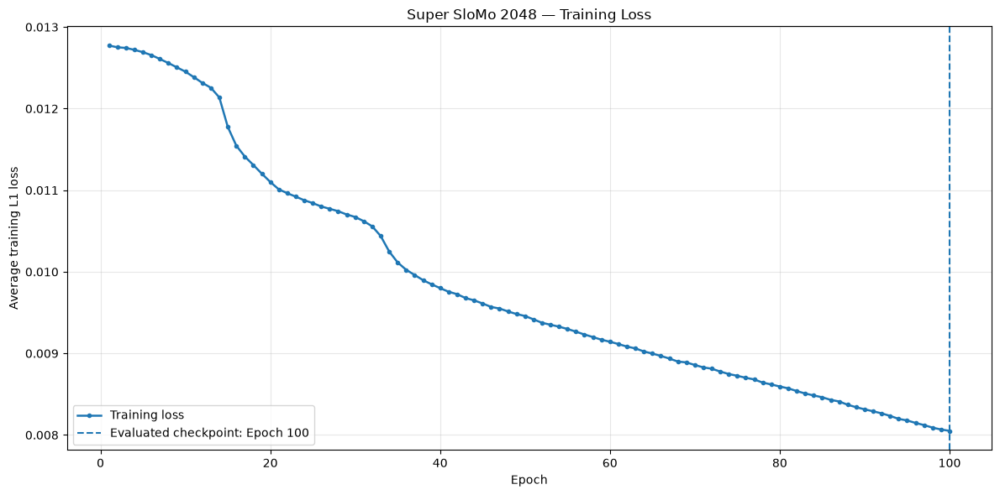


Loss graph saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_100/training_loss_all_epochs.png
Available epoch records: 100
Epoch range: 1 to 100

Model loaded successfully.
Checkpoint epoch: 100
Model parameters: 14748665
FSIM device: cuda
Test CSV rows: 1265
CSV columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
CSV row 10/1265 | Evaluated: 10 | Skipped: 0 | Patch MSE: 0.000203 | SSIM: 0.941349 | FSIM: 0.997236
CSV row 20/1265 | Evaluated: 20 | Skipped: 0 | Patch MSE: 0.000205 | SSIM: 0.941065 | FSIM: 0.997010
CSV row 30/1265 | Evaluated: 30 | Skipped: 0 | Patch MSE: 0.000200 | SSIM: 0.941350 | FSIM: 0.996924
CSV row 40/1265 | Evaluated: 40 | Skipped: 0 | Patch MSE: 0.000208 | SSIM: 0.940481 | FSIM: 0.997126
CSV row 50/1265 | Evaluated: 50 | Skipped: 0 | Patch MSE: 0.000217 | SSIM: 0.938342 | F

In [5]:

# ============================================================
# SUPER SLOMO 2048 — COMPLETE TESTING AND LOSS VISUALIZATION
# Checkpoint: Epoch 100
# Dataset: GOES_TestPatches_2048
#
# Outputs:
#   1. Training loss graph
#   2. Per-patch metrics CSV
#   3. Final evaluation summary CSV
#
# FSIM FIX: chromatic=False for grayscale satellite images
# ============================================================

import os
import sys
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from skimage.metrics import structural_similarity

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

MODEL_DIR = PROJECT_DIR / "SuperSloMo"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

HISTORY_PATH = LOG_DIR / "training_history.csv"

TEST_CSV = (
    PROJECT_DIR
    / "Dataset"
    / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

EVAL_EPOCH = 100

CHECKPOINT_PATH = (
    CHECKPOINT_DIR / f"epoch_{EVAL_EPOCH:03d}.pth"
)

# Must match the normalization used when creating patches.
BT_MIN_K = 200.0
BT_MAX_K = 320.0

DATA_MIN = 0.0
DATA_MAX = 1.0
DATA_RANGE = DATA_MAX - DATA_MIN

# Set True to calculate FSIM on the GPU.
FSIM_USE_GPU = True

OUTPUT_DIR = LOG_DIR / f"evaluation_epoch_{EVAL_EPOCH:03d}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOSS_PLOT_PATH = OUTPUT_DIR / "training_loss_all_epochs.png"

PATCH_RESULTS_PATH = (
    OUTPUT_DIR / "per_patch_metrics_epoch_100.csv"
)

SUMMARY_PATH = (
    OUTPUT_DIR / "test_metrics_summary_epoch_100.csv"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("SUPER SLOMO 2048 — TEST EVALUATION")
print("=" * 75)
print("Device:", device)
print("Checkpoint:", CHECKPOINT_PATH)
print("Test CSV:", TEST_CSV)
print("Output directory:", OUTPUT_DIR)

if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Test CSV does not exist:\n{TEST_CSV}"
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 81 checkpoint does not exist:\n"
        f"{CHECKPOINT_PATH}\n"
        "Verify that Epoch 100 completed and its checkpoint was saved."
    )

# ============================================================
# 2. PLOT LOSS FOR ALL AVAILABLE EPOCHS
# ============================================================

history_parts = []

# First read the original training history.
if HISTORY_PATH.exists():

    history_df = pd.read_csv(HISTORY_PATH)

    if {
        "epoch",
        "average_train_loss"
    }.issubset(history_df.columns):

        csv_losses = history_df[
            ["epoch", "average_train_loss"]
        ].copy()

        csv_losses["epoch"] = pd.to_numeric(
            csv_losses["epoch"], errors="coerce"
        )

        csv_losses["average_train_loss"] = pd.to_numeric(
            csv_losses["average_train_loss"], errors="coerce"
        )

        csv_losses = csv_losses.dropna()

        history_parts.append(csv_losses)

        print(
            "Loaded training-history records:",
            len(csv_losses)
        )

    else:
        print(
            "Warning: training_history.csv does not have "
            "the expected columns."
        )

else:
    print("Training-history CSV not found.")

# Recover losses from checkpoints for missing history entries.
for checkpoint_file in sorted(
    CHECKPOINT_DIR.glob("epoch_*.pth")
):

    try:
        checkpoint_data = torch.load(
            checkpoint_file,
            map_location="cpu",
            weights_only=False
        )

        if (
            isinstance(checkpoint_data, dict)
            and "epoch" in checkpoint_data
            and "average_train_loss" in checkpoint_data
        ):

            epoch_num = int(checkpoint_data["epoch"])
            loss_value = float(
                checkpoint_data["average_train_loss"]
            )

            if math.isfinite(loss_value):

                history_parts.append(
                    pd.DataFrame([{
                        "epoch": epoch_num,
                        "average_train_loss": loss_value
                    }])
                )

    except Exception as exc:
        print(
            f"Warning reading {checkpoint_file.name}: {exc}"
        )

if not history_parts:
    raise RuntimeError(
        "No training-loss history was found in the CSV "
        "or checkpoint files."
    )

loss_df = pd.concat(
    history_parts,
    ignore_index=True
)

loss_df["epoch"] = pd.to_numeric(
    loss_df["epoch"], errors="coerce"
)

loss_df["average_train_loss"] = pd.to_numeric(
    loss_df["average_train_loss"], errors="coerce"
)

loss_df = loss_df.dropna(
    subset=["epoch", "average_train_loss"]
)

loss_df["epoch"] = loss_df["epoch"].astype(int)

# CSV records take priority; checkpoint losses fill missing epochs.
loss_df = loss_df.drop_duplicates(
    subset=["epoch"],
    keep="first"
)

loss_df = loss_df.sort_values("epoch").reset_index(drop=True)

# Plot available epochs through Epoch 100.
loss_df = loss_df[loss_df["epoch"] <= EVAL_EPOCH].copy()

if loss_df.empty:
    raise RuntimeError(
        "No loss records found through Epoch 100."
    )

plt.figure(figsize=(12, 6))

plt.plot(
    loss_df["epoch"],
    loss_df["average_train_loss"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Training loss"
)

plt.axvline(
    EVAL_EPOCH,
    linestyle="--",
    linewidth=1.5,
    label=f"Evaluated checkpoint: Epoch {EVAL_EPOCH}"
)

plt.xlabel("Epoch")
plt.ylabel("Average training L1 loss")
plt.title("Super SloMo 2048 — Training Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    LOSS_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nLoss graph saved:", LOSS_PLOT_PATH)
print("Available epoch records:", len(loss_df))
print(
    "Epoch range:",
    loss_df["epoch"].min(),
    "to",
    loss_df["epoch"].max()
)

# Save the loss data used for the graph.
loss_df.to_csv(
    OUTPUT_DIR / "training_loss_plot_data.csv",
    index=False
)

# ============================================================
# 3. LOAD THE SAME SUPER SLOMO MODEL ARCHITECTURE
# ============================================================

if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import model as superslomo_module

net = superslomo_module.SuperSloMo().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError(
        "Checkpoint has no model_state_dict."
    )

checkpoint_epoch = int(checkpoint.get("epoch", -1))

if checkpoint_epoch != EVAL_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {EVAL_EPOCH}, "
        f"but checkpoint contains Epoch {checkpoint_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
net.eval()

print("\nModel loaded successfully.")
print("Checkpoint epoch:", checkpoint_epoch)
print(
    "Model parameters:",
    sum(p.numel() for p in net.parameters())
)

# ============================================================
# 4. IMPORT FSIM
# ============================================================

try:
    import piq
except ImportError as exc:
    raise ImportError(
        "PIQ is required for FSIM. Run this in a notebook cell:\n"
        "%pip install piq\n"
        "Then rerun this complete evaluation cell."
    ) from exc

fsim_device = (
    device
    if FSIM_USE_GPU and device.type == "cuda"
    else torch.device("cpu")
)

print("FSIM device:", fsim_device)

# ============================================================
# 5. LOAD TEST PATCH CSV
# ============================================================

test_df = pd.read_csv(TEST_CSV)

required_columns = [
    "img0_path",
    "img2_path",
    "gt_path",
    "mask_gt_path"
]

missing_columns = [
    column
    for column in required_columns
    if column not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing test CSV columns: {missing_columns}\n"
        f"Available columns: {list(test_df.columns)}"
    )

if len(test_df) == 0:
    raise RuntimeError("The test CSV is empty.")

print("Test CSV rows:", len(test_df))
print("CSV columns:", list(test_df.columns))

# ============================================================
# 6. PATCH LOADING FUNCTIONS
# ============================================================

def resolve_patch_path(path_value):
    path = Path(str(path_value))

    if path.is_absolute():
        return path

    candidate = PROJECT_DIR / path

    if candidate.exists():
        return candidate

    return path


def read_npy(path_value):
    path = resolve_patch_path(path_value)

    if not path.exists():
        raise FileNotFoundError(
            f"Patch file not found: {path}"
        )

    if path.suffix.lower() == ".npz":

        with np.load(path, allow_pickle=False) as archive:

            if len(archive.files) == 0:
                raise ValueError(
                    f"Empty NPZ file: {path}"
                )

            arr = archive[archive.files[0]]

    else:
        arr = np.load(
            path,
            allow_pickle=False
        )

    arr = np.asarray(
        arr,
        dtype=np.float32
    ).squeeze()

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, "
            f"got shape {arr.shape}: {path}"
        )

    return arr


def predict_midpoint(img0, img2):

    pred = net(
        img0,
        img2,
        t=0.5
    )

    if isinstance(pred, (tuple, list)):

        if len(pred) == 0:
            raise RuntimeError(
                "Model returned an empty tuple/list."
            )

        pred = pred[0]

    elif isinstance(pred, dict):

        raise TypeError(
            "Model returned a dictionary. Select the correct "
            "midpoint output for your model implementation."
        )

    if not torch.is_tensor(pred):
        raise TypeError(
            "The model prediction is not a tensor."
        )

    return pred


# ============================================================
# 7. INITIALIZE METRIC ACCUMULATORS
# ============================================================

total_squared_error = 0.0
total_absolute_error = 0.0
total_signed_error = 0.0

total_valid_pixels = 0

patch_ssim_values = []
patch_fsim_values = []

patch_results = []

evaluated_count = 0
skipped_count = 0

# ============================================================
# 8. EVALUATE THE TEST DATASET
# ============================================================

with torch.inference_mode():

    for row_index, row in test_df.iterrows():

        # ----------------------------------------------------
        # Load input frames, ground truth, and valid mask
        # ----------------------------------------------------
        img0_np = read_npy(row["img0_path"])
        img2_np = read_npy(row["img2_path"])
        gt_np = read_npy(row["gt_path"])
        mask_np = read_npy(row["mask_gt_path"])

        if not (
            img0_np.shape
            == img2_np.shape
            == gt_np.shape
            == mask_np.shape
        ):
            raise ValueError(
                f"Row {row_index}: shape mismatch.\n"
                f"img0={img0_np.shape}, "
                f"img2={img2_np.shape}, "
                f"gt={gt_np.shape}, "
                f"mask={mask_np.shape}"
            )

        # The model was trained on grayscale tensors [B, 1, H, W].
        img0 = torch.from_numpy(
            np.ascontiguousarray(img0_np)
        ).float()[None, None].to(device)

        img2 = torch.from_numpy(
            np.ascontiguousarray(img2_np)
        ).float()[None, None].to(device)

        # ----------------------------------------------------
        # Predict the intermediate frame
        # ----------------------------------------------------
        pred = predict_midpoint(img0, img2)

        if pred.shape != (1, 1, *gt_np.shape):
            raise RuntimeError(
                f"Row {row_index}: unexpected prediction shape "
                f"{tuple(pred.shape)}; expected "
                f"{(1, 1, *gt_np.shape)}."
            )

        pred_np = (
            pred[0, 0]
            .float()
            .cpu()
            .numpy()
        )

        # ----------------------------------------------------
        # Build valid-pixel mask
        # ----------------------------------------------------
        valid_mask = (
            np.isfinite(mask_np)
            & (mask_np > 0)
            & np.isfinite(gt_np)
            & np.isfinite(pred_np)
            & np.isfinite(img0_np)
            & np.isfinite(img2_np)
        )

        valid_count = int(valid_mask.sum())

        if valid_count == 0:

            skipped_count += 1

            warnings.warn(
                f"Skipping row {row_index}: no valid pixels."
            )

            del img0, img2, pred
            continue

        # ----------------------------------------------------
        # MSE, MAE, signed error on valid pixels
        # ----------------------------------------------------
        error = (
            pred_np[valid_mask] - gt_np[valid_mask]
        ).astype(np.float64)

        patch_mse = float(np.mean(error ** 2))
        patch_mae = float(np.mean(np.abs(error)))
        patch_bias = float(np.mean(error))

        total_squared_error += float(
            np.sum(error ** 2)
        )

        total_absolute_error += float(
            np.sum(np.abs(error))
        )

        total_signed_error += float(
            np.sum(error)
        )

        total_valid_pixels += valid_count

        # ----------------------------------------------------
        # Convert normalized values to BT in Kelvin
        # ----------------------------------------------------
        bt_scale = BT_MAX_K - BT_MIN_K

        pred_bt = (
            pred_np[valid_mask].astype(np.float64)
            * bt_scale + BT_MIN_K
        )

        gt_bt = (
            gt_np[valid_mask].astype(np.float64)
            * bt_scale + BT_MIN_K
        )

        bt_error = pred_bt - gt_bt

        patch_bt_mae = float(
            np.mean(np.abs(bt_error))
        )

        patch_bt_rmse = float(
            np.sqrt(np.mean(bt_error ** 2))
        )

        patch_bt_bias = float(
            np.mean(bt_error)
        )

        # ----------------------------------------------------
        # SSIM / FSIM preprocessing
        #
        # Replace invalid pixels in both images with the same
        # finite reference value so invalid areas do not
        # introduce artificial differences.
        # ----------------------------------------------------
        safe_gt = np.where(
            np.isfinite(gt_np),
            gt_np,
            0.0
        ).astype(np.float32)

        pred_perceptual = np.where(
            valid_mask,
            pred_np,
            safe_gt
        ).astype(np.float32)

        gt_perceptual = safe_gt.copy()

        # Clamp only perceptual metric inputs to [0, 1].
        pred_perceptual = np.clip(
            pred_perceptual,
            DATA_MIN,
            DATA_MAX
        )

        gt_perceptual = np.clip(
            gt_perceptual,
            DATA_MIN,
            DATA_MAX
        )

        # ----------------------------------------------------
        # SSIM
        # ----------------------------------------------------
        if min(gt_perceptual.shape) >= 7:

            ssim_value = float(
                structural_similarity(
                    gt_perceptual,
                    pred_perceptual,
                    data_range=DATA_RANGE,
                    gaussian_weights=True,
                    sigma=1.5,
                    use_sample_covariance=False
                )
            )

        else:
            ssim_value = float("nan")

        # ----------------------------------------------------
        # FSIM — CORRECTED FOR GRAYSCALE IMAGES
        # ----------------------------------------------------
        pred_fsim_tensor = torch.from_numpy(
            np.ascontiguousarray(
                pred_perceptual
            )
        )[None, None].to(fsim_device)

        gt_fsim_tensor = torch.from_numpy(
            np.ascontiguousarray(
                gt_perceptual
            )
        )[None, None].to(fsim_device)

        fsim_value = float(
            piq.fsim(
                pred_fsim_tensor,
                gt_fsim_tensor,
                data_range=DATA_RANGE,
                chromatic=False,
                reduction="mean"
            ).item()
        )

        patch_ssim_values.append(ssim_value)
        patch_fsim_values.append(fsim_value)

        # ----------------------------------------------------
        # Patch identity
        # ----------------------------------------------------
        if "patch_id" in test_df.columns:

            patch_name = str(row["patch_id"])

        else:

            patch_name = str(row_index)

        # ----------------------------------------------------
        # Store individual patch metrics
        # ----------------------------------------------------
        patch_results.append({
            "patch_index": int(row_index),
            "patch_id": patch_name,
            "valid_pixels": valid_count,
            "MSE": patch_mse,
            "PSNR_dB": (
                float("inf")
                if patch_mse == 0
                else float(
                    10.0 * np.log10(
                        (DATA_RANGE ** 2) / patch_mse
                    )
                )
            ),
            "SSIM": ssim_value,
            "FSIM": fsim_value,
            "BT_MAE_K": patch_bt_mae,
            "BT_RMSE_K": patch_bt_rmse,
            "BT_Bias_K": patch_bt_bias
        })

        evaluated_count += 1

        if (
            evaluated_count % 10 == 0
            or row_index == len(test_df) - 1
        ):

            print(
                f"CSV row {row_index + 1}/{len(test_df)} | "
                f"Evaluated: {evaluated_count} | "
                f"Skipped: {skipped_count} | "
                f"Patch MSE: {patch_mse:.6f} | "
                f"SSIM: {ssim_value:.6f} | "
                f"FSIM: {fsim_value:.6f}"
            )

        del img0, img2, pred
        del pred_fsim_tensor, gt_fsim_tensor

        # Do not empty the CUDA cache after every patch:
        # PyTorch can reuse cached memory on the next iteration.

# ============================================================
# 9. CHECK EVALUATION COMPLETION
# ============================================================

if evaluated_count == 0 or total_valid_pixels == 0:

    raise RuntimeError(
        "No valid test patches were evaluated. "
        "Check your test CSV paths and masks."
    )

print("\nEvaluation finished.")
print("Evaluated patches:", evaluated_count)
print("Skipped patches:", skipped_count)
print("Valid pixels:", total_valid_pixels)

# ============================================================
# 10. GLOBAL METRICS
# ============================================================

# Global pixel-weighted metrics.
global_mse = (
    total_squared_error / total_valid_pixels
)

global_mae = (
    total_absolute_error / total_valid_pixels
)

global_bias = (
    total_signed_error / total_valid_pixels
)

global_psnr = (
    float("inf")
    if global_mse == 0
    else float(
        10.0 * np.log10(
            (DATA_RANGE ** 2) / global_mse
        )
    )
)

# Mean patch-level SSIM and FSIM.
ssim_array = np.asarray(
    patch_ssim_values,
    dtype=np.float64
)

fsim_array = np.asarray(
    patch_fsim_values,
    dtype=np.float64
)

ssim_mean_patch = (
    float(np.nanmean(ssim_array))
    if np.isfinite(ssim_array).any()
    else float("nan")
)

fsim_mean_patch = (
    float(np.nanmean(fsim_array))
    if np.isfinite(fsim_array).any()
    else float("nan")
)

# Convert normalized errors to Kelvin.
BT_MAE_K = global_mae * bt_scale
BT_RMSE_K = np.sqrt(global_mse) * bt_scale
BT_Bias_K = global_bias * bt_scale

# ============================================================
# 11. CREATE FINAL SUMMARY TABLE
# ============================================================

summary = pd.DataFrame([{
    "Model": "Super SloMo",
    "Checkpoint": f"epoch_{EVAL_EPOCH:03d}.pth",
    "Evaluated_patches": evaluated_count,
    "Valid_pixels": total_valid_pixels,
    "MSE": global_mse,
    "PSNR_dB": global_psnr,
    "SSIM_mean_patch": ssim_mean_patch,
    "FSIM_mean_patch": fsim_mean_patch,
    "BT_MAE_K": BT_MAE_K,
    "BT_RMSE_K": BT_RMSE_K,
    "BT_Bias_K": BT_Bias_K
}])

# ============================================================
# 12. SAVE RESULTS
# ============================================================

patch_results_df = pd.DataFrame(patch_results)

patch_results_df.to_csv(
    PATCH_RESULTS_PATH,
    index=False
)

summary.to_csv(
    SUMMARY_PATH,
    index=False
)

# ============================================================
# 13. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 125)
print("SUPER SLOMO 2048 — FINAL TEST METRICS")
print("=" * 125)

print(
    summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)

print("\nFiles saved successfully:")
print("Training loss graph:", LOSS_PLOT_PATH)
print(
    "Loss graph data:",
    OUTPUT_DIR / "training_loss_plot_data.csv"
)
print("Per-patch metrics:", PATCH_RESULTS_PATH)
print("Final summary:", SUMMARY_PATH)

print("\nAll evaluation steps completed.")


SUPER SLOMO 2048 — TEST EVALUATION
Device: cuda
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_081.pth
Test CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_081
Loaded training-history records: 81


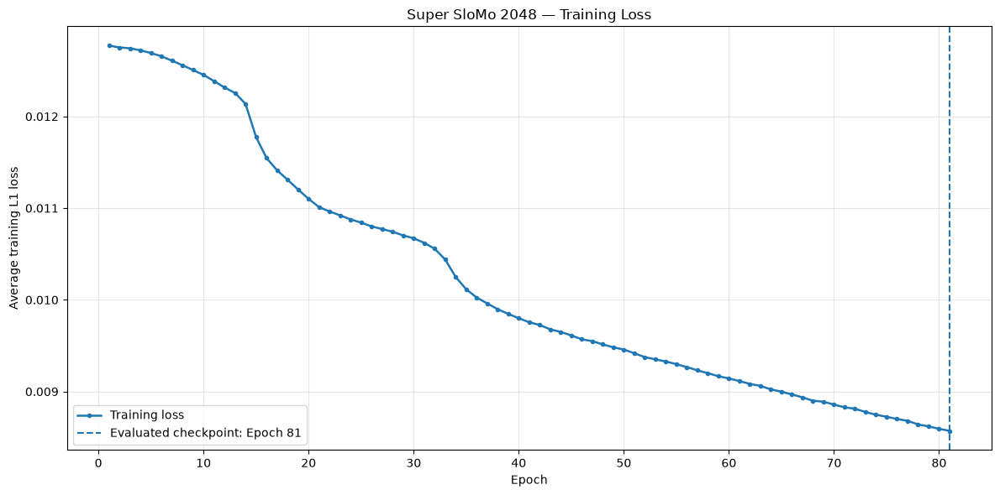


Loss graph saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_081/training_loss_all_epochs.png
Available epoch records: 81
Epoch range: 1 to 81

Model loaded successfully.
Checkpoint epoch: 81
Model parameters: 14748665
FSIM device: cuda
Test CSV rows: 1265
CSV columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
CSV row 10/1265 | Evaluated: 10 | Skipped: 0 | Patch MSE: 0.000261 | SSIM: 0.930817 | FSIM: 0.996743
CSV row 20/1265 | Evaluated: 20 | Skipped: 0 | Patch MSE: 0.000257 | SSIM: 0.932078 | FSIM: 0.996656
CSV row 30/1265 | Evaluated: 30 | Skipped: 0 | Patch MSE: 0.000251 | SSIM: 0.932303 | FSIM: 0.996485
CSV row 40/1265 | Evaluated: 40 | Skipped: 0 | Patch MSE: 0.000267 | SSIM: 0.930871 | FSIM: 0.996511
CSV row 50/1265 | Evaluated: 50 | Skipped: 0 | Patch MSE: 0.000269 | SSIM: 0.929822 | FSIM

In [2]:

# ============================================================
# SUPER SLOMO 2048 — COMPLETE TESTING AND LOSS VISUALIZATION
# Checkpoint: Epoch 81
# Dataset: GOES_TestPatches_2048
#
# Outputs:
#   1. Training loss graph
#   2. Per-patch metrics CSV
#   3. Final evaluation summary CSV
#
# FSIM FIX: chromatic=False for grayscale satellite images
# ============================================================

import os
import sys
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from skimage.metrics import structural_similarity

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

MODEL_DIR = PROJECT_DIR / "SuperSloMo"

CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048"
)

LOG_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
)

HISTORY_PATH = LOG_DIR / "training_history.csv"

TEST_CSV = (
    PROJECT_DIR
    / "Dataset"
    / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

EVAL_EPOCH = 81

CHECKPOINT_PATH = (
    CHECKPOINT_DIR / f"epoch_{EVAL_EPOCH:03d}.pth"
)

# Must match the normalization used when creating patches.
BT_MIN_K = 200.0
BT_MAX_K = 320.0

DATA_MIN = 0.0
DATA_MAX = 1.0
DATA_RANGE = DATA_MAX - DATA_MIN

# Set True to calculate FSIM on the GPU.
FSIM_USE_GPU = True

OUTPUT_DIR = LOG_DIR / f"evaluation_epoch_{EVAL_EPOCH:03d}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOSS_PLOT_PATH = OUTPUT_DIR / "training_loss_all_epochs.png"

PATCH_RESULTS_PATH = (
    OUTPUT_DIR / "per_patch_metrics_epoch_081.csv"
)

SUMMARY_PATH = (
    OUTPUT_DIR / "test_metrics_summary_epoch_081.csv"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("SUPER SLOMO 2048 — TEST EVALUATION")
print("=" * 75)
print("Device:", device)
print("Checkpoint:", CHECKPOINT_PATH)
print("Test CSV:", TEST_CSV)
print("Output directory:", OUTPUT_DIR)

if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Test CSV does not exist:\n{TEST_CSV}"
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Epoch 81 checkpoint does not exist:\n"
        f"{CHECKPOINT_PATH}\n"
        "Verify that Epoch 81 completed and its checkpoint was saved."
    )

# ============================================================
# 2. PLOT LOSS FOR ALL AVAILABLE EPOCHS
# ============================================================

history_parts = []

# First read the original training history.
if HISTORY_PATH.exists():

    history_df = pd.read_csv(HISTORY_PATH)

    if {
        "epoch",
        "average_train_loss"
    }.issubset(history_df.columns):

        csv_losses = history_df[
            ["epoch", "average_train_loss"]
        ].copy()

        csv_losses["epoch"] = pd.to_numeric(
            csv_losses["epoch"], errors="coerce"
        )

        csv_losses["average_train_loss"] = pd.to_numeric(
            csv_losses["average_train_loss"], errors="coerce"
        )

        csv_losses = csv_losses.dropna()

        history_parts.append(csv_losses)

        print(
            "Loaded training-history records:",
            len(csv_losses)
        )

    else:
        print(
            "Warning: training_history.csv does not have "
            "the expected columns."
        )

else:
    print("Training-history CSV not found.")

# Recover losses from checkpoints for missing history entries.
for checkpoint_file in sorted(
    CHECKPOINT_DIR.glob("epoch_*.pth")
):

    try:
        checkpoint_data = torch.load(
            checkpoint_file,
            map_location="cpu",
            weights_only=False
        )

        if (
            isinstance(checkpoint_data, dict)
            and "epoch" in checkpoint_data
            and "average_train_loss" in checkpoint_data
        ):

            epoch_num = int(checkpoint_data["epoch"])
            loss_value = float(
                checkpoint_data["average_train_loss"]
            )

            if math.isfinite(loss_value):

                history_parts.append(
                    pd.DataFrame([{
                        "epoch": epoch_num,
                        "average_train_loss": loss_value
                    }])
                )

    except Exception as exc:
        print(
            f"Warning reading {checkpoint_file.name}: {exc}"
        )

if not history_parts:
    raise RuntimeError(
        "No training-loss history was found in the CSV "
        "or checkpoint files."
    )

loss_df = pd.concat(
    history_parts,
    ignore_index=True
)

loss_df["epoch"] = pd.to_numeric(
    loss_df["epoch"], errors="coerce"
)

loss_df["average_train_loss"] = pd.to_numeric(
    loss_df["average_train_loss"], errors="coerce"
)

loss_df = loss_df.dropna(
    subset=["epoch", "average_train_loss"]
)

loss_df["epoch"] = loss_df["epoch"].astype(int)

# CSV records take priority; checkpoint losses fill missing epochs.
loss_df = loss_df.drop_duplicates(
    subset=["epoch"],
    keep="first"
)

loss_df = loss_df.sort_values("epoch").reset_index(drop=True)

# Plot available epochs through Epoch 81.
loss_df = loss_df[loss_df["epoch"] <= EVAL_EPOCH].copy()

if loss_df.empty:
    raise RuntimeError(
        "No loss records found through Epoch 81."
    )

plt.figure(figsize=(12, 6))

plt.plot(
    loss_df["epoch"],
    loss_df["average_train_loss"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Training loss"
)

plt.axvline(
    EVAL_EPOCH,
    linestyle="--",
    linewidth=1.5,
    label=f"Evaluated checkpoint: Epoch {EVAL_EPOCH}"
)

plt.xlabel("Epoch")
plt.ylabel("Average training L1 loss")
plt.title("Super SloMo 2048 — Training Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    LOSS_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nLoss graph saved:", LOSS_PLOT_PATH)
print("Available epoch records:", len(loss_df))
print(
    "Epoch range:",
    loss_df["epoch"].min(),
    "to",
    loss_df["epoch"].max()
)

# Save the loss data used for the graph.
loss_df.to_csv(
    OUTPUT_DIR / "training_loss_plot_data.csv",
    index=False
)

# ============================================================
# 3. LOAD THE SAME SUPER SLOMO MODEL ARCHITECTURE
# ============================================================

if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import model as superslomo_module

net = superslomo_module.SuperSloMo().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError(
        "Checkpoint has no model_state_dict."
    )

checkpoint_epoch = int(checkpoint.get("epoch", -1))

if checkpoint_epoch != EVAL_EPOCH:
    raise RuntimeError(
        f"Expected Epoch {EVAL_EPOCH}, "
        f"but checkpoint contains Epoch {checkpoint_epoch}."
    )

net.load_state_dict(checkpoint["model_state_dict"])
net.eval()

print("\nModel loaded successfully.")
print("Checkpoint epoch:", checkpoint_epoch)
print(
    "Model parameters:",
    sum(p.numel() for p in net.parameters())
)

# ============================================================
# 4. IMPORT FSIM
# ============================================================

try:
    import piq
except ImportError as exc:
    raise ImportError(
        "PIQ is required for FSIM. Run this in a notebook cell:\n"
        "%pip install piq\n"
        "Then rerun this complete evaluation cell."
    ) from exc

fsim_device = (
    device
    if FSIM_USE_GPU and device.type == "cuda"
    else torch.device("cpu")
)

print("FSIM device:", fsim_device)

# ============================================================
# 5. LOAD TEST PATCH CSV
# ============================================================

test_df = pd.read_csv(TEST_CSV)

required_columns = [
    "img0_path",
    "img2_path",
    "gt_path",
    "mask_gt_path"
]

missing_columns = [
    column
    for column in required_columns
    if column not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing test CSV columns: {missing_columns}\n"
        f"Available columns: {list(test_df.columns)}"
    )

if len(test_df) == 0:
    raise RuntimeError("The test CSV is empty.")

print("Test CSV rows:", len(test_df))
print("CSV columns:", list(test_df.columns))

# ============================================================
# 6. PATCH LOADING FUNCTIONS
# ============================================================

def resolve_patch_path(path_value):
    path = Path(str(path_value))

    if path.is_absolute():
        return path

    candidate = PROJECT_DIR / path

    if candidate.exists():
        return candidate

    return path


def read_npy(path_value):
    path = resolve_patch_path(path_value)

    if not path.exists():
        raise FileNotFoundError(
            f"Patch file not found: {path}"
        )

    if path.suffix.lower() == ".npz":

        with np.load(path, allow_pickle=False) as archive:

            if len(archive.files) == 0:
                raise ValueError(
                    f"Empty NPZ file: {path}"
                )

            arr = archive[archive.files[0]]

    else:
        arr = np.load(
            path,
            allow_pickle=False
        )

    arr = np.asarray(
        arr,
        dtype=np.float32
    ).squeeze()

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, "
            f"got shape {arr.shape}: {path}"
        )

    return arr


def predict_midpoint(img0, img2):

    pred = net(
        img0,
        img2,
        t=0.5
    )

    if isinstance(pred, (tuple, list)):

        if len(pred) == 0:
            raise RuntimeError(
                "Model returned an empty tuple/list."
            )

        pred = pred[0]

    elif isinstance(pred, dict):

        raise TypeError(
            "Model returned a dictionary. Select the correct "
            "midpoint output for your model implementation."
        )

    if not torch.is_tensor(pred):
        raise TypeError(
            "The model prediction is not a tensor."
        )

    return pred


# ============================================================
# 7. INITIALIZE METRIC ACCUMULATORS
# ============================================================

total_squared_error = 0.0
total_absolute_error = 0.0
total_signed_error = 0.0

total_valid_pixels = 0

patch_ssim_values = []
patch_fsim_values = []

patch_results = []

evaluated_count = 0
skipped_count = 0

# ============================================================
# 8. EVALUATE THE TEST DATASET
# ============================================================

with torch.inference_mode():

    for row_index, row in test_df.iterrows():

        # ----------------------------------------------------
        # Load input frames, ground truth, and valid mask
        # ----------------------------------------------------
        img0_np = read_npy(row["img0_path"])
        img2_np = read_npy(row["img2_path"])
        gt_np = read_npy(row["gt_path"])
        mask_np = read_npy(row["mask_gt_path"])

        if not (
            img0_np.shape
            == img2_np.shape
            == gt_np.shape
            == mask_np.shape
        ):
            raise ValueError(
                f"Row {row_index}: shape mismatch.\n"
                f"img0={img0_np.shape}, "
                f"img2={img2_np.shape}, "
                f"gt={gt_np.shape}, "
                f"mask={mask_np.shape}"
            )

        # The model was trained on grayscale tensors [B, 1, H, W].
        img0 = torch.from_numpy(
            np.ascontiguousarray(img0_np)
        ).float()[None, None].to(device)

        img2 = torch.from_numpy(
            np.ascontiguousarray(img2_np)
        ).float()[None, None].to(device)

        # ----------------------------------------------------
        # Predict the intermediate frame
        # ----------------------------------------------------
        pred = predict_midpoint(img0, img2)

        if pred.shape != (1, 1, *gt_np.shape):
            raise RuntimeError(
                f"Row {row_index}: unexpected prediction shape "
                f"{tuple(pred.shape)}; expected "
                f"{(1, 1, *gt_np.shape)}."
            )

        pred_np = (
            pred[0, 0]
            .float()
            .cpu()
            .numpy()
        )

        # ----------------------------------------------------
        # Build valid-pixel mask
        # ----------------------------------------------------
        valid_mask = (
            np.isfinite(mask_np)
            & (mask_np > 0)
            & np.isfinite(gt_np)
            & np.isfinite(pred_np)
            & np.isfinite(img0_np)
            & np.isfinite(img2_np)
        )

        valid_count = int(valid_mask.sum())

        if valid_count == 0:

            skipped_count += 1

            warnings.warn(
                f"Skipping row {row_index}: no valid pixels."
            )

            del img0, img2, pred
            continue

        # ----------------------------------------------------
        # MSE, MAE, signed error on valid pixels
        # ----------------------------------------------------
        error = (
            pred_np[valid_mask] - gt_np[valid_mask]
        ).astype(np.float64)

        patch_mse = float(np.mean(error ** 2))
        patch_mae = float(np.mean(np.abs(error)))
        patch_bias = float(np.mean(error))

        total_squared_error += float(
            np.sum(error ** 2)
        )

        total_absolute_error += float(
            np.sum(np.abs(error))
        )

        total_signed_error += float(
            np.sum(error)
        )

        total_valid_pixels += valid_count

        # ----------------------------------------------------
        # Convert normalized values to BT in Kelvin
        # ----------------------------------------------------
        bt_scale = BT_MAX_K - BT_MIN_K

        pred_bt = (
            pred_np[valid_mask].astype(np.float64)
            * bt_scale + BT_MIN_K
        )

        gt_bt = (
            gt_np[valid_mask].astype(np.float64)
            * bt_scale + BT_MIN_K
        )

        bt_error = pred_bt - gt_bt

        patch_bt_mae = float(
            np.mean(np.abs(bt_error))
        )

        patch_bt_rmse = float(
            np.sqrt(np.mean(bt_error ** 2))
        )

        patch_bt_bias = float(
            np.mean(bt_error)
        )

        # ----------------------------------------------------
        # SSIM / FSIM preprocessing
        #
        # Replace invalid pixels in both images with the same
        # finite reference value so invalid areas do not
        # introduce artificial differences.
        # ----------------------------------------------------
        safe_gt = np.where(
            np.isfinite(gt_np),
            gt_np,
            0.0
        ).astype(np.float32)

        pred_perceptual = np.where(
            valid_mask,
            pred_np,
            safe_gt
        ).astype(np.float32)

        gt_perceptual = safe_gt.copy()

        # Clamp only perceptual metric inputs to [0, 1].
        pred_perceptual = np.clip(
            pred_perceptual,
            DATA_MIN,
            DATA_MAX
        )

        gt_perceptual = np.clip(
            gt_perceptual,
            DATA_MIN,
            DATA_MAX
        )

        # ----------------------------------------------------
        # SSIM
        # ----------------------------------------------------
        if min(gt_perceptual.shape) >= 7:

            ssim_value = float(
                structural_similarity(
                    gt_perceptual,
                    pred_perceptual,
                    data_range=DATA_RANGE,
                    gaussian_weights=True,
                    sigma=1.5,
                    use_sample_covariance=False
                )
            )

        else:
            ssim_value = float("nan")

        # ----------------------------------------------------
        # FSIM — CORRECTED FOR GRAYSCALE IMAGES
        # ----------------------------------------------------
        pred_fsim_tensor = torch.from_numpy(
            np.ascontiguousarray(
                pred_perceptual
            )
        )[None, None].to(fsim_device)

        gt_fsim_tensor = torch.from_numpy(
            np.ascontiguousarray(
                gt_perceptual
            )
        )[None, None].to(fsim_device)

        fsim_value = float(
            piq.fsim(
                pred_fsim_tensor,
                gt_fsim_tensor,
                data_range=DATA_RANGE,
                chromatic=False,
                reduction="mean"
            ).item()
        )

        patch_ssim_values.append(ssim_value)
        patch_fsim_values.append(fsim_value)

        # ----------------------------------------------------
        # Patch identity
        # ----------------------------------------------------
        if "patch_id" in test_df.columns:

            patch_name = str(row["patch_id"])

        else:

            patch_name = str(row_index)

        # ----------------------------------------------------
        # Store individual patch metrics
        # ----------------------------------------------------
        patch_results.append({
            "patch_index": int(row_index),
            "patch_id": patch_name,
            "valid_pixels": valid_count,
            "MSE": patch_mse,
            "PSNR_dB": (
                float("inf")
                if patch_mse == 0
                else float(
                    10.0 * np.log10(
                        (DATA_RANGE ** 2) / patch_mse
                    )
                )
            ),
            "SSIM": ssim_value,
            "FSIM": fsim_value,
            "BT_MAE_K": patch_bt_mae,
            "BT_RMSE_K": patch_bt_rmse,
            "BT_Bias_K": patch_bt_bias
        })

        evaluated_count += 1

        if (
            evaluated_count % 10 == 0
            or row_index == len(test_df) - 1
        ):

            print(
                f"CSV row {row_index + 1}/{len(test_df)} | "
                f"Evaluated: {evaluated_count} | "
                f"Skipped: {skipped_count} | "
                f"Patch MSE: {patch_mse:.6f} | "
                f"SSIM: {ssim_value:.6f} | "
                f"FSIM: {fsim_value:.6f}"
            )

        del img0, img2, pred
        del pred_fsim_tensor, gt_fsim_tensor

        # Do not empty the CUDA cache after every patch:
        # PyTorch can reuse cached memory on the next iteration.

# ============================================================
# 9. CHECK EVALUATION COMPLETION
# ============================================================

if evaluated_count == 0 or total_valid_pixels == 0:

    raise RuntimeError(
        "No valid test patches were evaluated. "
        "Check your test CSV paths and masks."
    )

print("\nEvaluation finished.")
print("Evaluated patches:", evaluated_count)
print("Skipped patches:", skipped_count)
print("Valid pixels:", total_valid_pixels)

# ============================================================
# 10. GLOBAL METRICS
# ============================================================

# Global pixel-weighted metrics.
global_mse = (
    total_squared_error / total_valid_pixels
)

global_mae = (
    total_absolute_error / total_valid_pixels
)

global_bias = (
    total_signed_error / total_valid_pixels
)

global_psnr = (
    float("inf")
    if global_mse == 0
    else float(
        10.0 * np.log10(
            (DATA_RANGE ** 2) / global_mse
        )
    )
)

# Mean patch-level SSIM and FSIM.
ssim_array = np.asarray(
    patch_ssim_values,
    dtype=np.float64
)

fsim_array = np.asarray(
    patch_fsim_values,
    dtype=np.float64
)

ssim_mean_patch = (
    float(np.nanmean(ssim_array))
    if np.isfinite(ssim_array).any()
    else float("nan")
)

fsim_mean_patch = (
    float(np.nanmean(fsim_array))
    if np.isfinite(fsim_array).any()
    else float("nan")
)

# Convert normalized errors to Kelvin.
BT_MAE_K = global_mae * bt_scale
BT_RMSE_K = np.sqrt(global_mse) * bt_scale
BT_Bias_K = global_bias * bt_scale

# ============================================================
# 11. CREATE FINAL SUMMARY TABLE
# ============================================================

summary = pd.DataFrame([{
    "Model": "Super SloMo",
    "Checkpoint": f"epoch_{EVAL_EPOCH:03d}.pth",
    "Evaluated_patches": evaluated_count,
    "Valid_pixels": total_valid_pixels,
    "MSE": global_mse,
    "PSNR_dB": global_psnr,
    "SSIM_mean_patch": ssim_mean_patch,
    "FSIM_mean_patch": fsim_mean_patch,
    "BT_MAE_K": BT_MAE_K,
    "BT_RMSE_K": BT_RMSE_K,
    "BT_Bias_K": BT_Bias_K
}])

# ============================================================
# 12. SAVE RESULTS
# ============================================================

patch_results_df = pd.DataFrame(patch_results)

patch_results_df.to_csv(
    PATCH_RESULTS_PATH,
    index=False
)

summary.to_csv(
    SUMMARY_PATH,
    index=False
)

# ============================================================
# 13. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 125)
print("SUPER SLOMO 2048 — FINAL TEST METRICS")
print("=" * 125)

print(
    summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)

print("\nFiles saved successfully:")
print("Training loss graph:", LOSS_PLOT_PATH)
print(
    "Loss graph data:",
    OUTPUT_DIR / "training_loss_plot_data.csv"
)
print("Per-patch metrics:", PATCH_RESULTS_PATH)
print("Final summary:", SUMMARY_PATH)

print("\nAll evaluation steps completed.")


In [3]:

# ============================================================
# FIX: DEFINE PROJECT PATHS AND LOAD TEST CSV
# Run this cell before Code 1
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import torch

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = (
    PROJECT_DIR
    / "Dataset"
    / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "logs"
    / "SuperSloMo_2048"
    / "evaluation_epoch_100"
)

VIS_DIR = OUTPUT_DIR / "review_visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Test CSV:", TEST_CSV)
print("Output directory:", OUTPUT_DIR)
print("Visualization directory:", VIS_DIR)

if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Test CSV not found: {TEST_CSV}"
    )

test_df = pd.read_csv(TEST_CSV)

print("\nTest CSV loaded successfully.")
print("Number of test patches:", len(test_df))
print("CSV columns:", test_df.columns.tolist())

required_columns = [
    "img0_path",
    "img2_path",
    "gt_path"
]

missing = [
    col for col in required_columns
    if col not in test_df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}\n"
        f"Available columns: {test_df.columns.tolist()}"
    )

print("\nReady to run Code 1.")


Project directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation
Test CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_100
Visualization directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_100/review_visualizations

Test CSV loaded successfully.
Number of test patches: 1265
CSV columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']

Ready to run Code 1.


In [5]:
# ============================================================
# HELPER FUNCTION: LOAD NUMPY PATCH FILES
# Run this cell before the visualization cell
# ============================================================

from pathlib import Path
import numpy as np

def read_npy(file_path):
    """Load a .npy patch and return a NumPy array."""
    file_path = Path(file_path)

    if not file_path.is_absolute():
        file_path = PROJECT_DIR / file_path

    if not file_path.exists():
        raise FileNotFoundError(
            f"Patch file not found:\n{file_path}"
        )

    arr = np.load(file_path, allow_pickle=False)
    arr = np.asarray(arr, dtype=np.float32)
    arr = np.squeeze(arr)

    # Convert channel-first image (C,H,W) to (H,W,C)
    if arr.ndim == 3 and arr.shape[0] in (1, 3, 4):
        arr = np.transpose(arr, (1, 2, 0))

    # Convert grayscale (H,W,1) to (H,W)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr[..., 0]

    if arr.ndim not in (2, 3):
        raise ValueError(
            f"Unexpected patch shape {arr.shape} in {file_path}"
        )

    # Replace invalid values safely
    arr = np.nan_to_num(
        arr,
        nan=0.0,
        posinf=1.0,
        neginf=0.0
    )

    return arr

print("read_npy() defined successfully.")

read_npy() defined successfully.


In [6]:
# Check the first test patch
row = test_df.iloc[0]

img0_np = read_npy(row["img0_path"])
img2_np = read_npy(row["img2_path"])
gt_np   = read_npy(row["gt_path"])

print("Input frame 1 shape:", img0_np.shape)
print("Input frame 2 shape:", img2_np.shape)
print("Ground truth shape:", gt_np.shape)

print("\nValue ranges:")
print("Input 1:", np.nanmin(img0_np), "to", np.nanmax(img0_np))
print("Input 2:", np.nanmin(img2_np), "to", np.nanmax(img2_np))
print("Ground truth:", np.nanmin(gt_np), "to", np.nanmax(gt_np))

Input frame 1 shape: (2048, 2048)
Input frame 2 shape: (2048, 2048)
Ground truth shape: (2048, 2048)

Value ranges:
Input 1: 0.0 to 0.87841797
Input 2: 0.0 to 0.8833008
Ground truth: 0.0 to 0.88916016


In [8]:
# ============================================================
# DEFINE COMPUTE DEVICE
# ============================================================

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA available:", torch.cuda.is_available())
else:
    print("Running on CPU.")

Selected device: cuda
GPU: NVIDIA H200 NVL
CUDA available: True


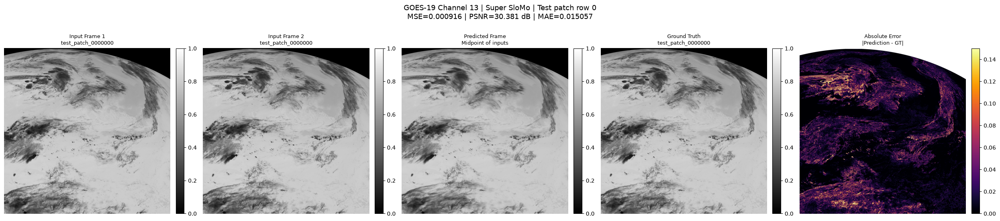

Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/evaluation_epoch_100/review_visualizations/test_patch_00000_comparison.png
Patch dimensions: (2048, 2048)
MSE:  0.00091610
PSNR: 30.3806 dB
MAE:  0.01505681


In [13]:

# ============================================================
# CODE 1: INPUTS + PREDICTION + GT + ERROR MAP
# Uses your actual GOES_TestPatches_2048 test CSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch

VIS_DIR = OUTPUT_DIR / "review_visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

PATCH_ROW = 0                 # Change to inspect another test patch
ERROR_SCALE = 0.15            # Error-map display limit, normalized [0,1]

row = test_df.iloc[PATCH_ROW]

img0_np = read_npy(row["img0_path"])
img2_np = read_npy(row["img2_path"])
gt_np = read_npy(row["gt_path"])

img0 = torch.from_numpy(
    np.ascontiguousarray(img0_np)
).float()[None, None].to(device)

img2 = torch.from_numpy(
    np.ascontiguousarray(img2_np)
).float()[None, None].to(device)

net.eval()
with torch.inference_mode():
    pred = net(img0, img2, t=0.5)
    if isinstance(pred, (tuple, list)):
        pred = pred[0]

pred_np = pred[0, 0].detach().cpu().numpy()

if not (img0_np.shape == img2_np.shape == gt_np.shape == pred_np.shape):
    raise ValueError("Input, prediction and GT patch dimensions do not match.")

# Optional timestamps: use them if your CSV contains them.
def timestamp_from_row(row, candidate_columns, fallback):
    for col in candidate_columns:
        if col in row.index and pd.notna(row[col]):
            return str(row[col])
    return fallback

time0 = timestamp_from_row(
    row, ["time_0", "timestamp_0", "input0_time"],
    Path(str(row["img0_path"])).stem
)
time2 = timestamp_from_row(
    row, ["time_2", "timestamp_2", "input2_time"],
    Path(str(row["img2_path"])).stem
)
time_gt = timestamp_from_row(
    row, ["time_1", "target_time", "timestamp_gt"],
    Path(str(row["gt_path"])).stem
)

# Mask invalid target pixels if a ground-truth mask is available.
if "mask_gt_path" in row.index and pd.notna(row["mask_gt_path"]):
    mask = read_npy(row["mask_gt_path"]) > 0
else:
    mask = np.ones_like(gt_np, dtype=bool)

valid = (
    mask & np.isfinite(img0_np) & np.isfinite(img2_np)
    & np.isfinite(gt_np) & np.isfinite(pred_np)
)

error_map = np.where(valid, np.abs(pred_np - gt_np), np.nan)

if valid.any():
    err = pred_np[valid].astype(np.float64) - gt_np[valid].astype(np.float64)
    mse = np.mean(err**2)
    mae = np.mean(np.abs(err))
    psnr = np.inf if mse == 0 else 10 * np.log10(1.0 / mse)
else:
    mse, mae, psnr = np.nan, np.nan, np.nan

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

panels = [
    (img0_np, f"Input Frame 1\n{time0}", "gray", 0, 1),
    (img2_np, f"Input Frame 2\n{time2}", "gray", 0, 1),
    (pred_np, f"Predicted Frame\nMidpoint of inputs", "gray", 0, 1),
    (gt_np, f"Ground Truth\n{time_gt}", "gray", 0, 1),
    (error_map, "Absolute Error\n|Prediction - GT|", "inferno", 0, ERROR_SCALE),
]

for ax, (arr, title, cmap, vmin, vmax) in zip(axes, panels):
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.suptitle(
    f"GOES-19 Channel 13 | Super SloMo | Test patch row {PATCH_ROW}\n"
    f"MSE={mse:.6f} | PSNR={psnr:.3f} dB | MAE={mae:.6f}",
    fontsize=13
)
plt.tight_layout()

save_path = VIS_DIR / f"test_patch_{PATCH_ROW:05d}_comparison.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", save_path)
print("Patch dimensions:", pred_np.shape)
print(f"MSE:  {mse:.8f}")
print(f"PSNR: {psnr:.4f} dB")
print(f"MAE:  {mae:.8f}")


Raw GOES directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_100.pth
Checkpoint epoch: 100
Device: cuda

Selected files:
Input 1: 2026-07-14 01:40:20 /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950140209_e20261950149529_c20261950149580.nc
GT     : 2026-07-14 02:10:20 /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950210209_e20261950219529_c20261950219561.nc
Input 2: 2026-07-14 02:40:20 /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950240209_e20261950249529_c20261950249548.nc
Actual input-to-GT interval: 30.0 minutes
Actual GT-to-input interval: 30.0 mi

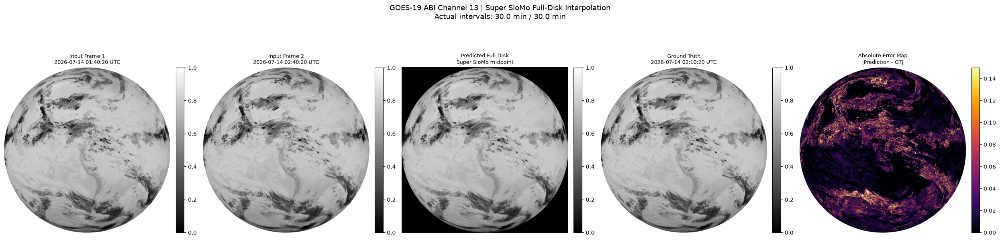

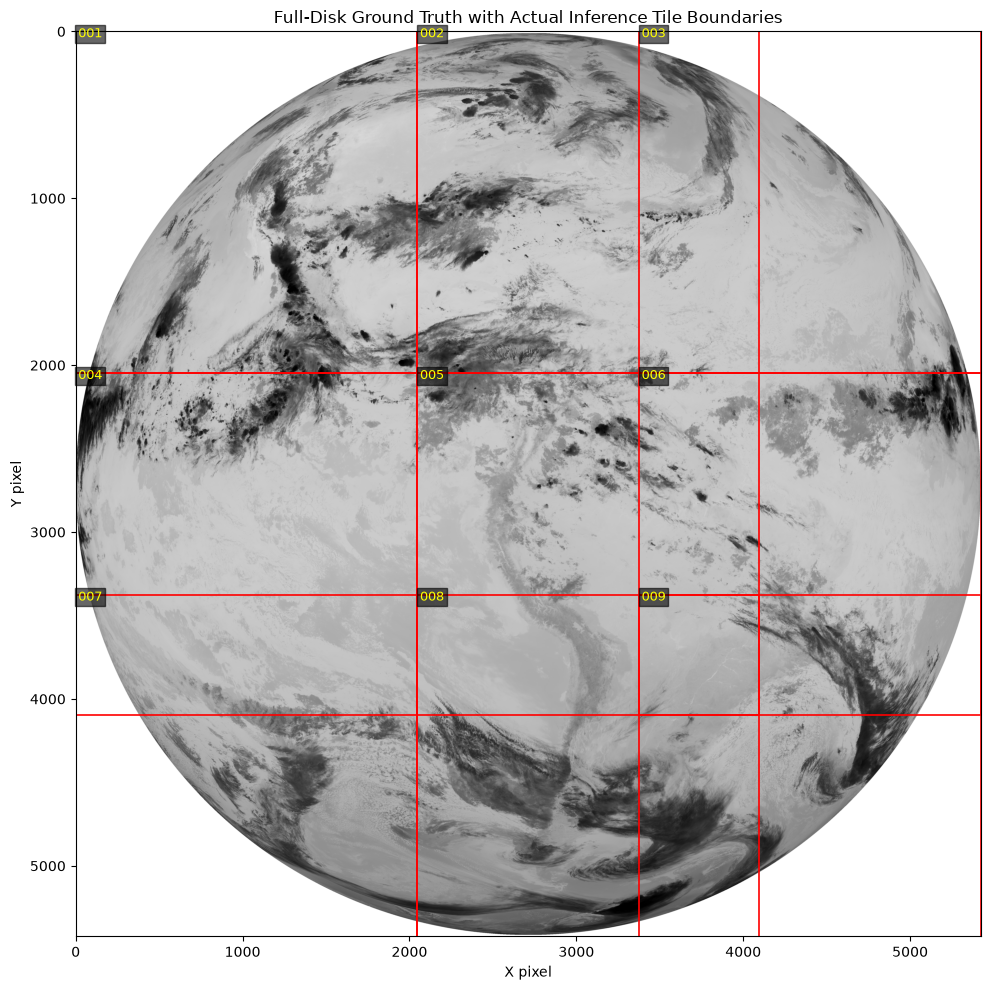


FULL-DISK METRICS (normalized data, range 0-1)
Valid pixels: 23,046,036
Valid coverage: 78.34%
MSE : 0.00168484
MAE : 0.02131255
RMSE: 0.04104676
PSNR: 27.7344 dB

Saved results:
Five-panel full disk: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/full_disk_five_panel_comparison.png
Tile-location map: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/full_disk_tile_locations.png
Tile manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/full_disk_tile_manifest.csv
Saved individual tiles: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/saved_patches


In [14]:

# ============================================================
# CODE 2: GOES-19 FULL-DISK SUPER SLOMO INFERENCE
# Inputs approximately 30 min before/after the GT timestamp
# Saves reconstructed full disk + tile manifest + tile arrays
# ============================================================

import os
import re
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xarray as xr

from pathlib import Path
from datetime import datetime, timedelta

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)
MODEL_DIR = PROJECT_DIR / "SuperSloMo"
CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints_NEW" / "SuperSloMo_2048" / "epoch_100.pth"
)

# Raw directory was not specified in the attached notebook.
# Try the project-relative location and the previously used workspace location.
RAW_DIR_CANDIDATES = [
    PROJECT_DIR / "Dataset" / "Raw" / "GOES" / "GOES",
    Path("/home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/"
         "Dataset/Raw/GOES/GOES"),
]

RAW_DIR = next(
    (p for p in RAW_DIR_CANDIDATES if p.exists()),
    None
)

if RAW_DIR is None:
    raise FileNotFoundError(
        "Could not find the raw GOES directory. Checked:\n" +
        "\n".join(str(p) for p in RAW_DIR_CANDIDATES)
    )

# Set this to the actual target/ground-truth timestamp in UTC.
TARGET_TIME = datetime.strptime(
    "2026-07-14 02:10:20", "%Y-%m-%d %H:%M:%S"
)

# The selected files must be within this tolerance of the desired times.
TIME_TOLERANCE_SECONDS = 180

TILE_SIZE = 2048
BT_MIN_K = 200.0
BT_MAX_K = 320.0

# GOES-19 ABI Channel 13 Planck calibration values
FK1 = 10860.4004
FK2 = 1395.1899
BC1 = 0.07481
BC2 = 0.99975

OUT_DIR = (
    PROJECT_DIR / "logs" / "SuperSloMo_2048"
    / "full_disk_review_30min"
)
PATCH_DIR = OUT_DIR / "saved_patches"
PATCH_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Raw GOES directory:", RAW_DIR)
print("Output directory:", OUT_DIR)

# ------------------------------------------------------------
# 1. Load the model checkpoint used by your notebook
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import model as superslomo_module

net = superslomo_module.SuperSloMo().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError("Checkpoint does not contain model_state_dict.")

net.load_state_dict(checkpoint["model_state_dict"])
net.eval()

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))
print("Device:", device)

# ------------------------------------------------------------
# 2. Find GOES full-disk Channel 13 NetCDF files
# ------------------------------------------------------------
nc_files = sorted(RAW_DIR.glob("OR_ABI-L1b-RadF-M6C13_G19*.nc"))

if not nc_files:
    raise FileNotFoundError(
        f"No GOES-19 full-disk Channel 13 NetCDF files found in {RAW_DIR}"
    )

def goes_start_time(path):
    # GOES filename contains sYYYYJJJHHMMSS plus a fractional digit.
    match = re.search(r"_s(\d{13})", path.name)
    if not match:
        return None
    return datetime.strptime(match.group(1), "%Y%j%H%M%S")

timed_files = []
for path in nc_files:
    stamp = goes_start_time(path)
    if stamp is not None:
        timed_files.append((stamp, path))

if not timed_files:
    raise RuntimeError("Could not parse timestamps from GOES filenames.")

timed_files.sort(key=lambda item: item[0])

def nearest_file(desired_time, label):
    stamp, path = min(
        timed_files,
        key=lambda item: abs((item[0] - desired_time).total_seconds())
    )
    delta = abs((stamp - desired_time).total_seconds())

    if delta > TIME_TOLERANCE_SECONDS:
        raise RuntimeError(
            f"No GOES file close enough to {label} time {desired_time}. "
            f"Nearest file is {path.name}, time={stamp}, difference={delta:.1f}s. "
            "Change TARGET_TIME or TIME_TOLERANCE_SECONDS."
        )

    return stamp, path

time0, path0 = nearest_file(
    TARGET_TIME - timedelta(minutes=30), "input-0"
)
time_gt, path_gt = nearest_file(TARGET_TIME, "ground-truth")
time2, path2 = nearest_file(
    TARGET_TIME + timedelta(minutes=30), "input-2"
)

print("\nSelected files:")
print("Input 1:", time0, path0)
print("GT     :", time_gt, path_gt)
print("Input 2:", time2, path2)
print("Actual input-to-GT interval:",
      (time_gt - time0).total_seconds() / 60, "minutes")
print("Actual GT-to-input interval:",
      (time2 - time_gt).total_seconds() / 60, "minutes")

# ------------------------------------------------------------
# 3. Convert radiance to brightness temperature and normalize
# ------------------------------------------------------------
def read_goes_normalized_bt(nc_path):
    with xr.open_dataset(nc_path) as ds:
        if "Rad" not in ds:
            raise KeyError(f"'Rad' variable missing from {nc_path}")
        rad = np.asarray(ds["Rad"].values.squeeze(), dtype=np.float32)

    if rad.ndim != 2:
        raise ValueError(
            f"Expected 2D full-disk radiance, got {rad.shape}: {nc_path}"
        )

    valid = np.isfinite(rad) & (rad > 0)

    bt = np.full(rad.shape, np.nan, dtype=np.float32)
    bt[valid] = (
        FK2 / np.log((FK1 / rad[valid]) + 1.0) - BC1
    ) / BC2

    valid_bt = np.isfinite(bt)
    bt[~valid_bt] = np.nan

    normalized = np.full(bt.shape, np.nan, dtype=np.float32)
    normalized[valid_bt] = np.clip(
        (bt[valid_bt] - BT_MIN_K) / (BT_MAX_K - BT_MIN_K),
        0.0, 1.0
    )

    return normalized

print("\nReading and calibrating full-disk GOES images...")
full0 = read_goes_normalized_bt(path0)
full_gt = read_goes_normalized_bt(path_gt)
full2 = read_goes_normalized_bt(path2)

if not (full0.shape == full_gt.shape == full2.shape):
    raise ValueError(
        f"Full-disk shapes differ: {full0.shape}, {full_gt.shape}, {full2.shape}"
    )

H, W = full_gt.shape
print("Full-disk dimensions:", (H, W))

# ------------------------------------------------------------
# 4. Create edge-aligned tiles that cover the complete disk
# ------------------------------------------------------------
def tile_starts(length, tile_size):
    if length < tile_size:
        raise ValueError(
            f"Image dimension {length} is smaller than tile size {tile_size}"
        )
    starts = list(range(0, length - tile_size + 1, tile_size))
    final_start = length - tile_size
    if starts[-1] != final_start:
        starts.append(final_start)
    return starts

ys = tile_starts(H, TILE_SIZE)
xs = tile_starts(W, TILE_SIZE)

print("Tile rows:", len(ys))
print("Tile columns:", len(xs))
print("Total tiles:", len(ys) * len(xs))
print("Tile size:", TILE_SIZE)

# Smooth weights help blend overlapping tile edges.
hann = np.hanning(TILE_SIZE).astype(np.float32)
blend_weight = np.maximum(np.outer(hann, hann), 1e-3)

sum_pred = np.zeros((H, W), dtype=np.float64)
sum_weight = np.zeros((H, W), dtype=np.float64)

# Keep actual tile positions and saved file paths for Code 3.
manifest = []

def model_predict_patch(a0, a2):
    # Invalid source pixels are filled with zero for model input.
    a0_input = np.nan_to_num(a0, nan=0.0, posinf=0.0, neginf=0.0)
    a2_input = np.nan_to_num(a2, nan=0.0, posinf=0.0, neginf=0.0)

    t0 = torch.from_numpy(
        np.ascontiguousarray(a0_input)
    ).float()[None, None].to(device)

    t2 = torch.from_numpy(
        np.ascontiguousarray(a2_input)
    ).float()[None, None].to(device)

    with torch.inference_mode():
        out = net(t0, t2, t=0.5)
        if isinstance(out, (tuple, list)):
            out = out[0]

    if not torch.is_tensor(out):
        raise TypeError("Super SloMo output is not a tensor.")

    pred = out[0, 0].detach().float().cpu().numpy()

    if pred.shape != (TILE_SIZE, TILE_SIZE):
        raise RuntimeError(
            f"Unexpected model output shape {pred.shape}"
        )

    return np.clip(pred, 0.0, 1.0)

tile_number = 0

for y in ys:
    for x in xs:
        tile_number += 1
        region = np.s_[y:y+TILE_SIZE, x:x+TILE_SIZE]

        a0 = full0[region]
        a2 = full2[region]
        gt = full_gt[region]

        pred = model_predict_patch(a0, a2)

        sum_pred[region] += pred * blend_weight
        sum_weight[region] += blend_weight

        # Save each tile to explain the tiled inference process.
        tile_id = f"tile_{tile_number:03d}_x{x}_y{y}"

        p0 = PATCH_DIR / f"{tile_id}_input0.npy"
        p2 = PATCH_DIR / f"{tile_id}_input2.npy"
        pg = PATCH_DIR / f"{tile_id}_gt.npy"
        pp = PATCH_DIR / f"{tile_id}_pred.npy"

        np.save(p0, a0)
        np.save(p2, a2)
        np.save(pg, gt)
        np.save(pp, pred)

        manifest.append({
            "patch_id": tile_id,
            "x_start": x,
            "y_start": y,
            "width": TILE_SIZE,
            "height": TILE_SIZE,
            "input0_timestamp": time0.isoformat(),
            "gt_timestamp": time_gt.isoformat(),
            "input2_timestamp": time2.isoformat(),
            "input0_path": str(p0),
            "input2_path": str(p2),
            "gt_path": str(pg),
            "pred_path": str(pp)
        })

        print(
            f"Tile {tile_number:02d}/{len(xs)*len(ys)} "
            f"| x={x}, y={y} completed"
        )

full_pred = np.full((H, W), np.nan, dtype=np.float32)
covered = sum_weight > 0
full_pred[covered] = (
    sum_pred[covered] / sum_weight[covered]
).astype(np.float32)

# Evaluate only pixels valid in both inputs and the target.
valid_eval = (
    np.isfinite(full0) & np.isfinite(full2)
    & np.isfinite(full_gt) & np.isfinite(full_pred)
)

full_error = np.full((H, W), np.nan, dtype=np.float32)
full_error[valid_eval] = np.abs(
    full_pred[valid_eval] - full_gt[valid_eval]
)

# Save reconstructed arrays and tile manifest.
np.save(OUT_DIR / "input_frame_1_full_disk.npy", full0)
np.save(OUT_DIR / "input_frame_2_full_disk.npy", full2)
np.save(OUT_DIR / "ground_truth_full_disk.npy", full_gt)
np.save(OUT_DIR / "predicted_full_disk.npy", full_pred)
np.save(OUT_DIR / "absolute_error_full_disk.npy", full_error)

manifest_df = pd.DataFrame(manifest)
manifest_path = OUT_DIR / "full_disk_tile_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

# ------------------------------------------------------------
# 5. Display all five full-disk panels with timestamps
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(25, 7))

panels = [
    (full0, f"Input Frame 1\n{time0:%Y-%m-%d %H:%M:%S} UTC",
     "gray", 0, 1),
    (full2, f"Input Frame 2\n{time2:%Y-%m-%d %H:%M:%S} UTC",
     "gray", 0, 1),
    (full_pred, "Predicted Full Disk\nSuper SloMo midpoint",
     "gray", 0, 1),
    (full_gt, f"Ground Truth\n{time_gt:%Y-%m-%d %H:%M:%S} UTC",
     "gray", 0, 1),
    (full_error, "Absolute Error Map\n|Prediction - GT|",
     "inferno", 0, 0.15),
]

for ax, (arr, title, cmap, vmin, vmax) in zip(axes, panels):
    im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.suptitle(
    "GOES-19 ABI Channel 13 | Super SloMo Full-Disk Interpolation\n"
    f"Actual intervals: {((time_gt-time0).total_seconds()/60):.1f} min / "
    f"{((time2-time_gt).total_seconds()/60):.1f} min",
    fontsize=13
)
plt.tight_layout()

comparison_path = OUT_DIR / "full_disk_five_panel_comparison.png"
plt.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. Display the actual tile positions used for inference
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(full_gt, cmap="gray", vmin=0, vmax=1)

from matplotlib.patches import Rectangle

for item in manifest:
    x, y = item["x_start"], item["y_start"]
    ax.add_patch(Rectangle(
        (x, y), TILE_SIZE, TILE_SIZE,
        edgecolor="red", facecolor="none", linewidth=1.2
    ))
    ax.text(
        x + 15, y + 35, item["patch_id"].split("_")[1],
        color="yellow", fontsize=9,
        bbox=dict(facecolor="black", alpha=0.6, pad=2)
    )

ax.set_title("Full-Disk Ground Truth with Actual Inference Tile Boundaries")
ax.set_xlabel("X pixel")
ax.set_ylabel("Y pixel")
plt.tight_layout()

tile_map_path = OUT_DIR / "full_disk_tile_locations.png"
plt.savefig(tile_map_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 7. Calculate full-disk metrics over valid common pixels
# ------------------------------------------------------------
if valid_eval.any():
    e = (
        full_pred[valid_eval].astype(np.float64)
        - full_gt[valid_eval].astype(np.float64)
    )
    mse = np.mean(e**2)
    mae = np.mean(np.abs(e))
    rmse = np.sqrt(mse)
    psnr = np.inf if mse == 0 else 10 * np.log10(1.0 / mse)

    print("\nFULL-DISK METRICS (normalized data, range 0-1)")
    print(f"Valid pixels: {int(valid_eval.sum()):,}")
    print(f"Valid coverage: {100*valid_eval.mean():.2f}%")
    print(f"MSE : {mse:.8f}")
    print(f"MAE : {mae:.8f}")
    print(f"RMSE: {rmse:.8f}")
    print(f"PSNR: {psnr:.4f} dB")
else:
    print("No common valid pixels available for metric calculation.")

print("\nSaved results:")
print("Five-panel full disk:", comparison_path)
print("Tile-location map:", tile_map_path)
print("Tile manifest:", manifest_path)
print("Saved individual tiles:", PATCH_DIR)


In [15]:
# ============================================================
# GOES-19 SUPERSLOMO — 10-MINUTE INTERVAL EXPERIMENT
#
# Input 1      : Frame at t
# Ground truth : Frame at t + 10 minutes
# Input 2      : Frame at t + 20 minutes
# Prediction   : Frame at t + 10 minutes
# ============================================================

# Temporal experiment
INTERVAL_MINUTES = 10
TIME_TOLERANCE_SECONDS = 60

# Model inference — retain your existing settings
TILE_SIZE = 2048
TILE_OVERLAP = 0
PAD_MULTIPLE = 32

# Output folder: separate from the 30-minute experiment
OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "SuperSloMo_10min_experiment"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"
GROUND_TRUTH_DIR = OUTPUT_DIR / "ground_truth"
INPUT0_DIR = OUTPUT_DIR / "input_t"
INPUT2_DIR = OUTPUT_DIR / "input_t_plus_20"

METRICS_CSV = OUTPUT_DIR / "metrics_10min.csv"
SUMMARY_CSV = OUTPUT_DIR / "summary_10min.csv"
SKIPPED_CSV = OUTPUT_DIR / "skipped_samples.csv"

for directory in [
    OUTPUT_DIR,
    PREDICTION_DIR,
    GROUND_TRUTH_DIR,
    INPUT0_DIR,
    INPUT2_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Experiment: GOES-19 SuperSloMo — 10-minute interval")
print("Required input spacing:", INTERVAL_MINUTES * 2, "minutes")
print("Prediction offset:", INTERVAL_MINUTES, "minutes")
print("Output directory:", OUTPUT_DIR)

Experiment: GOES-19 SuperSloMo — 10-minute interval
Required input spacing: 20 minutes
Prediction offset: 10 minutes
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/SuperSloMo_10min_experiment


In [21]:
# ============================================================
# SELECT FRAMES FOR 10-MINUTE PREDICTION
# ============================================================

interval = pd.Timedelta(minutes=INTERVAL_MINUTES)

t0 = timestamp
t1 = t0 + interval
t2 = t0 + (2 * interval)

# The timeline dictionary should map timestamps to file paths.
if t0 in timeline and t1 in timeline and t2 in timeline:
    input0_path = timeline[t0]   # t
    gt_path = timeline[t1]       # t + 10 min
    input2_path = timeline[t2]   # t + 20 min

    print("Input frame 1 :", t0, "->", input0_path)
    print("Ground truth  :", t1, "->", gt_path)
    print("Input frame 2 :", t2, "->", input2_path)
else:
    print("Skipping: one or more required timestamps are missing.")

NameError: name 'timestamp' is not defined

In [20]:
# ============================================================
# BUILD 10-MINUTE INTERVAL PREDICTION SAMPLES
# Input 1: t | Ground truth: t+10 | Input 2: t+20
# ============================================================

INTERVAL_MINUTES = 10
TIME_TOLERANCE_SECONDS = 60

timestamps = sorted(timeline.keys())

expected_delta = pd.Timedelta(minutes=INTERVAL_MINUTES)
tolerance = pd.Timedelta(seconds=TIME_TOLERANCE_SECONDS)

samples = []
used_targets = set()

for t0 in timestamps:
    # Find the target and second input using actual timeline keys.
    target_time = t0 + expected_delta
    input2_time = t0 + 2 * expected_delta

    def find_nearest_timestamp(target):
        candidates = [
            ts for ts in timestamps
            if abs(ts - target) <= tolerance
        ]
        if not candidates:
            return None
        return min(candidates, key=lambda ts: abs(ts - target))

    t1 = find_nearest_timestamp(target_time)
    t2 = find_nearest_timestamp(input2_time)

    if t1 is None or t2 is None:
        continue

    if t1 in used_targets:
        continue

    samples.append({
        "time_0": t0,
        "time_1": t1,
        "time_2": t2,
        "input_0": timeline[t0],
        "target": timeline[t1],
        "input_2": timeline[t2],
    })

    used_targets.add(t1)

samples.sort(key=lambda sample: sample["time_1"])

print("10-minute experiment")
print("Valid samples:", len(samples))

if samples:
    s = samples[0]
    print("Input 1:", s["time_0"], s["input_0"])
    print("Ground truth:", s["time_1"], s["target"])
    print("Input 2:", s["time_2"], s["input_2"])

    assert abs((s["time_1"] - s["time_0"]).total_seconds() - 600) <= TIME_TOLERANCE_SECONDS
    assert abs((s["time_2"] - s["time_1"]).total_seconds() - 600) <= TIME_TOLERANCE_SECONDS
else:
    raise RuntimeError(
        "No valid 10-minute samples found. Check the timeline timestamps."
    )

10-minute experiment
Valid samples: 253
Input 1: 2026-07-14 01:50:20 /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950150209_e20261950159529_c20261950159567.nc
Ground truth: 2026-07-14 02:00:20 /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950200209_e20261950209531_c20261950209572.nc
Input 2: 2026-07-14 02:10:20 /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950210209_e20261950219529_c20261950219561.nc


In [19]:
# ============================================================
# BUILD TIMELINE FROM GOES-19 TEST CSV
# 10-minute cadence
# ============================================================

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TEST_CSV = PROJECT_DIR / "Dataset" / "GOES_TestNEW" / "test_triplets.csv"

df = pd.read_csv(TEST_CSV)

required = {"input_0", "target", "input_2", "time_0", "time_1", "time_2"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing CSV columns: {missing}")

# Convert timestamp columns to datetime
for col in ["time_0", "time_1", "time_2"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Build a timestamp -> NetCDF path dictionary using all CSV frames
timeline = {}

for _, row in df.iterrows():
    for time_col, path_col in [
        ("time_0", "input_0"),
        ("time_1", "target"),
        ("time_2", "input_2"),
    ]:
        ts = row[time_col]
        path = row[path_col]

        if pd.notna(ts) and pd.notna(path):
            timeline.setdefault(ts, str(path))

timeline = dict(sorted(timeline.items()))

timestamps = list(timeline.keys())

print("Timeline created successfully.")
print("Unique timestamps:", len(timestamps))
print("First timestamp:", timestamps[0] if timestamps else "None")
print("First file:", timeline[timestamps[0]] if timestamps else "None")

if not timestamps:
    raise RuntimeError("No valid timestamps found in the test CSV.")

# Build 10-minute interpolation samples:
# Input 0 = t
# Ground truth = t + 10 minutes
# Input 2 = t + 20 minutes

INTERVAL_MINUTES = 10
TIME_TOLERANCE_SECONDS = 60

samples = []
tolerance = pd.Timedelta(seconds=TIME_TOLERANCE_SECONDS)

for t0 in timestamps:
    expected_t1 = t0 + pd.Timedelta(minutes=10)
    expected_t2 = t0 + pd.Timedelta(minutes=20)

    def nearest_time(target):
        candidates = [
            ts for ts in timestamps
            if abs(ts - target) <= tolerance
        ]
        return min(candidates, key=lambda ts: abs(ts - target)) if candidates else None

    t1 = nearest_time(expected_t1)
    t2 = nearest_time(expected_t2)

    if t1 is None or t2 is None:
        continue

    # Confirm actual timing
    gap01 = (t1 - t0).total_seconds() / 60
    gap02 = (t2 - t0).total_seconds() / 60

    if abs(gap01 - 10) > 1 or abs(gap02 - 20) > 1:
        continue

    samples.append({
        "time_0": t0,
        "time_1": t1,
        "time_2": t2,
        "input_0": timeline[t0],
        "target": timeline[t1],
        "input_2": timeline[t2],
    })

print("10-minute samples found:", len(samples))

if not samples:
    raise RuntimeError(
        "No 10-minute samples found. Check the timestamps in test_triplets.csv."
    )

print("\nFirst sample:")
print("Input at t:      ", samples[0]["time_0"])
print("Ground truth t+10:", samples[0]["time_1"])
print("Input at t+20:   ", samples[0]["time_2"])

Timeline created successfully.
Unique timestamps: 255
First timestamp: 2026-07-14 01:50:20
First file: /home/jupyter-kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/Raw/GOES/GOES/OR_ABI-L1b-RadF-M6C13_G19_s20261950150209_e20261950159529_c20261950159567.nc
10-minute samples found: 253

First sample:
Input at t:       2026-07-14 01:50:20
Ground truth t+10: 2026-07-14 02:00:20
Input at t+20:    2026-07-14 02:10:20


Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/individual_patch_figures/tile_001_x0_y0_comparison.png


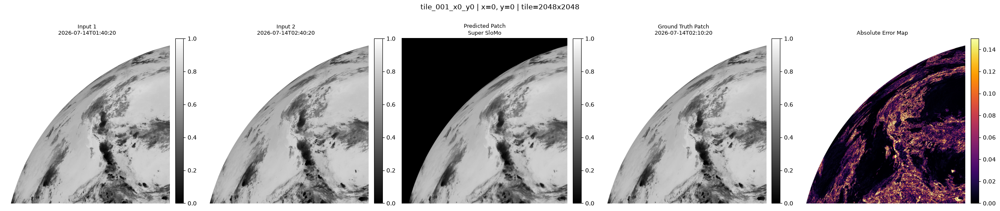

Tile MSE=0.00253472 | PSNR=25.9607 dB | MAE=0.02687708
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/individual_patch_figures/tile_001_x0_y0_comparison.png
Tile MSE=0.00253472 | PSNR=25.9607 dB | MAE=0.02687708
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/individual_patch_figures/tile_002_x2048_y0_comparison.png
Tile MSE=0.00209937 | PSNR=26.7791 dB | MAE=0.02453066
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/individual_patch_figures/tile_003_x3376_y0_comparison.png
Tile MSE=0.00069866 | PSNR=31.5573 dB | MAE=0.01270694
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo_2048/full_disk_review_30min/individual_patch_figures/tile_004_x0_y2048_comparison.png
Tile MSE=0.00108926 | PSNR=29.6287 dB | MAE=0.01562790
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/logs/SuperSloMo

In [18]:

# ============================================================
# CODE 3: VISUALIZE SAVED PREDICTION PATCHES
# Run after Code 2
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PATCH_MANIFEST = OUT_DIR / "full_disk_tile_manifest.csv"
PATCH_FIG_DIR = OUT_DIR / "individual_patch_figures"
PATCH_FIG_DIR.mkdir(parents=True, exist_ok=True)

manifest_df = pd.read_csv(PATCH_MANIFEST)

# Select tile row 0, 1, 2, ... from the manifest.
PATCH_INDEX = 0

def load_saved_array(path):
    p = Path(str(path))
    if not p.exists():
        raise FileNotFoundError(f"Saved tile not found: {p}")
    return np.load(p, allow_pickle=False).squeeze().astype(np.float32)

def plot_one_tile(item, show=True, save=True):
    a0 = load_saved_array(item["input0_path"])
    a2 = load_saved_array(item["input2_path"])
    gt = load_saved_array(item["gt_path"])
    pred = load_saved_array(item["pred_path"])

    error = np.abs(pred - gt)

    t0 = str(item["input0_timestamp"])
    tg = str(item["gt_timestamp"])
    t2 = str(item["input2_timestamp"])

    fig, axes = plt.subplots(1, 5, figsize=(24, 5.5))

    panels = [
        (a0, f"Input 1\n{t0}", "gray", 0, 1),
        (a2, f"Input 2\n{t2}", "gray", 0, 1),
        (pred, "Predicted Patch\nSuper SloMo", "gray", 0, 1),
        (gt, f"Ground Truth Patch\n{tg}", "gray", 0, 1),
        (error, "Absolute Error Map", "inferno", 0, 0.15),
    ]

    for ax, (arr, title, cmap, vmin, vmax) in zip(axes, panels):
        im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

    x, y = int(item["x_start"]), int(item["y_start"])
    fig.suptitle(
        f"{item['patch_id']} | x={x}, y={y} | "
        f"tile={int(item['width'])}x{int(item['height'])}",
        fontsize=12
    )
    plt.tight_layout()

    save_path = PATCH_FIG_DIR / f"{item['patch_id']}_comparison.png"
    if save:
        plt.savefig(save_path, dpi=250, bbox_inches="tight")
        print("Saved:", save_path)

    if show:
        plt.show()
    else:
        plt.close(fig)

    valid = np.isfinite(pred) & np.isfinite(gt)
    if valid.any():
        err = pred[valid].astype(np.float64) - gt[valid].astype(np.float64)
        mse = np.mean(err**2)
        psnr = np.inf if mse == 0 else 10 * np.log10(1.0 / mse)
        mae = np.mean(np.abs(err))
        print(f"Tile MSE={mse:.8f} | PSNR={psnr:.4f} dB | MAE={mae:.8f}")

# Display one selected tile
if PATCH_INDEX < 0 or PATCH_INDEX >= len(manifest_df):
    raise IndexError(
        f"PATCH_INDEX must be between 0 and {len(manifest_df)-1}"
    )

plot_one_tile(manifest_df.iloc[PATCH_INDEX])

# Save all individual tile comparison figures.
for i in range(len(manifest_df)):
    plot_one_tile(manifest_df.iloc[i], show=False, save=True)

print("\nPatch visualizations saved in:", PATCH_FIG_DIR)


Device: cuda
Test manifest: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_100.pth

Selected patch index: 0
Patch ID: test_patch_0000000
Patch shape: (2048, 2048)
Super SloMo checkpoint loaded.
Checkpoint epoch: 100
Prediction completed: (2048, 2048)

========== SUPER SLOMO METRICS ==========
Valid pixels : 3,988,789
MSE          : 0.00040356
MAE          : 0.00991133
RMSE         : 0.02008887
PSNR         : 33.9409 dB
BT-MAE       : 1.1894 K
BT-RMSE      : 2.4107 K
BT-Bias      : 0.0471 K

Timestamps:
Input 1: First input frame (T)
GT: Ground truth (middle frame)
Input 2: Second input frame (T+interval)


TypeError: Axes.set_title() missing 1 required positional argument: 'label'

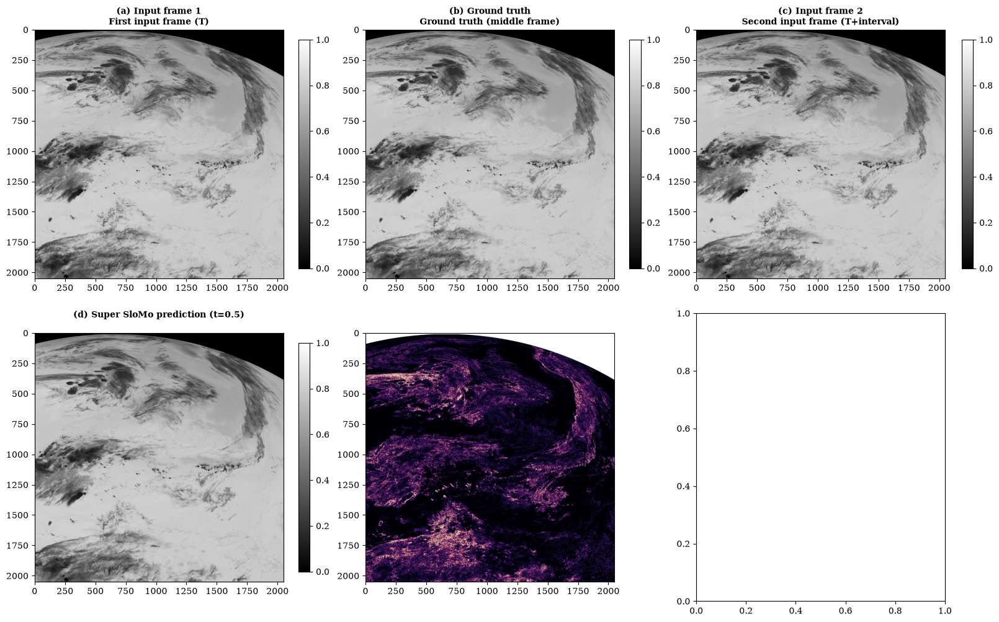

In [4]:
# ================================================================
# GOES-19 SUPER SLOMO — PUBLICATION-READY VISUALIZATION
# Based on the attached superslomo notebook
#
# Panels:
#   (a) Input I0
#   (b) Ground truth I1
#   (c) Input I2
#   (d) Super SloMo prediction at t=0.5
#   (e) Absolute error map in Kelvin
#   (f) Signed error map in Kelvin
#
# Checkpoint: epoch_100.pth
# Patch size: 2048 x 2048
# Normalization: BT in [200 K, 320 K]
# ================================================================

import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path

# ================================================================
# 1. PATHS AND SETTINGS — MATCH THE ATTACHED NOTEBOOK
# ================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

MODEL_DIR = PROJECT_DIR / "SuperSloMo"

TEST_CSV = (
    PROJECT_DIR
    / "Dataset"
    / "GOES_TestPatches_2048"
    / "test_patches.csv"
)

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "SuperSloMo_2048"
    / "epoch_100.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "SuperSloMo_epoch100_visualizations"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this to visualize another test patch.
PATCH_INDEX = 0

BT_MIN_K = 200.0
BT_MAX_K = 320.0
BT_RANGE_K = BT_MAX_K - BT_MIN_K

ERROR_PERCENTILE = 99

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Test manifest:", TEST_CSV)
print("Checkpoint:", CHECKPOINT_PATH)

if not TEST_CSV.exists():
    raise FileNotFoundError(f"Test CSV not found: {TEST_CSV}")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}"
    )

# ================================================================
# 2. LOAD TEST-PATCH MANIFEST
# ================================================================

test_df = pd.read_csv(TEST_CSV)

required_columns = [
    "img0_path",
    "gt_path",
    "img2_path",
    "mask_gt_path",
]

missing_columns = [
    c for c in required_columns
    if c not in test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in test manifest: {missing_columns}\n"
        f"Available columns: {list(test_df.columns)}"
    )

if not 0 <= PATCH_INDEX < len(test_df):
    raise IndexError(
        f"PATCH_INDEX must be between 0 and {len(test_df)-1}"
    )

row = test_df.iloc[PATCH_INDEX]

print("\nSelected patch index:", PATCH_INDEX)

if "patch_id" in test_df.columns:
    print("Patch ID:", row["patch_id"])

# ================================================================
# 3. LOAD THE FOUR PATCH FILES
# ================================================================

def resolve_path(value):
    path = Path(str(value))

    if path.is_absolute():
        return path

    project_candidate = PROJECT_DIR / path

    if project_candidate.exists():
        return project_candidate

    return path


def read_npy(value):
    path = resolve_path(value)

    if not path.exists():
        raise FileNotFoundError(f"Patch file not found: {path}")

    if path.suffix.lower() == ".npz":
        with np.load(path, allow_pickle=False) as archive:
            if not archive.files:
                raise ValueError(f"Empty NPZ file: {path}")
            arr = archive[archive.files[0]]
    else:
        arr = np.load(path, allow_pickle=False)

    arr = np.asarray(arr, dtype=np.float32).squeeze()

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got {arr.shape}: {path}"
        )

    return arr


img0_np = read_npy(row["img0_path"])
gt_np = read_npy(row["gt_path"])
img2_np = read_npy(row["img2_path"])
mask_np = read_npy(row["mask_gt_path"]) > 0

if not (
    img0_np.shape
    == gt_np.shape
    == img2_np.shape
    == mask_np.shape
):
    raise ValueError(
        "Input, GT, and mask shapes differ: "
        f"I0={img0_np.shape}, GT={gt_np.shape}, "
        f"I2={img2_np.shape}, mask={mask_np.shape}"
    )

print("Patch shape:", gt_np.shape)

# ================================================================
# 4. LOAD THE EXACT SUPER SLOMO ARCHITECTURE AND CHECKPOINT
# ================================================================

if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import model as superslomo_module

net = superslomo_module.SuperSloMo().to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise KeyError(
        "Checkpoint does not contain model_state_dict."
    )

net.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

net.eval()

print("Super SloMo checkpoint loaded.")
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

# ================================================================
# 5. PREDICT THE MIDDLE FRAME
# ================================================================

def make_tensor(image):
    image = np.nan_to_num(
        image,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return torch.from_numpy(
        np.ascontiguousarray(image)
    ).float()[None, None].to(DEVICE)


img0_tensor = make_tensor(img0_np)
img2_tensor = make_tensor(img2_np)

with torch.inference_mode():
    output = net(
        img0_tensor,
        img2_tensor,
        t=0.5
    )

# Match the output handling in the attached notebook.
if isinstance(output, (tuple, list)):
    if len(output) == 0:
        raise RuntimeError("Super SloMo returned an empty output.")
    output = output[0]

if not torch.is_tensor(output):
    raise TypeError(
        f"Unexpected Super SloMo output type: {type(output)}"
    )

prediction_np = (
    output[0, 0]
    .detach()
    .cpu()
    .numpy()
    .astype(np.float32)
)

if prediction_np.shape != gt_np.shape:
    raise ValueError(
        f"Prediction shape {prediction_np.shape} "
        f"does not match GT shape {gt_np.shape}"
    )

print("Prediction completed:", prediction_np.shape)

# ================================================================
# 6. COMPUTE ABSOLUTE AND SIGNED ERROR MAPS
# ================================================================

# The notebook's normalized brightness-temperature data
# follows BT = normalized_value * 120 + 200 K.
# Therefore, differences in normalized units are multiplied by
# 120 to obtain differences in Kelvin.

valid = (
    mask_np
    & np.isfinite(gt_np)
    & np.isfinite(prediction_np)
)

if not np.any(valid):
    raise ValueError("No valid GT pixels available.")

signed_error_k = np.full(
    gt_np.shape, np.nan, dtype=np.float32
)

signed_error_k[valid] = (
    prediction_np[valid] - gt_np[valid]
) * BT_RANGE_K

absolute_error_k = np.abs(signed_error_k)

# Metrics on valid pixels only.
diff = prediction_np[valid] - gt_np[valid]

mse = float(np.mean(diff ** 2))
mae = float(np.mean(np.abs(diff)))
rmse = float(np.sqrt(mse))

psnr = (
    float("inf")
    if mse == 0
    else float(10 * np.log10(1.0 / mse))
)

bt_mae = float(np.mean(absolute_error_k[valid]))
bt_rmse = float(np.sqrt(np.mean(signed_error_k[valid] ** 2)))
bt_bias = float(np.mean(signed_error_k[valid]))

abs_limit = max(
    float(np.percentile(absolute_error_k[valid], ERROR_PERCENTILE)),
    0.1
)

signed_limit = max(
    float(np.percentile(np.abs(signed_error_k[valid]), ERROR_PERCENTILE)),
    0.1
)

print("\n========== SUPER SLOMO METRICS ==========")
print(f"Valid pixels : {int(valid.sum()):,}")
print(f"MSE          : {mse:.8f}")
print(f"MAE          : {mae:.8f}")
print(f"RMSE         : {rmse:.8f}")
print(f"PSNR         : {psnr:.4f} dB")
print(f"BT-MAE       : {bt_mae:.4f} K")
print(f"BT-RMSE      : {bt_rmse:.4f} K")
print(f"BT-Bias      : {bt_bias:.4f} K")

# ================================================================
# 7. GET TIMESTAMPS IF AVAILABLE IN THE MANIFEST
# ================================================================

# The attached test-patch manifest may contain only paths and masks.
# Do not invent exact timestamps if they are not present.

def get_timestamp(row, key):
    if key not in row.index or pd.isna(row[key]):
        return None
    return str(row[key])


time0 = get_timestamp(row, "time_0")
time1 = get_timestamp(row, "time_1")
time2 = get_timestamp(row, "time_2")

# Some patch manifests store only the source triplet index.
# If timestamp columns are absent, use descriptive relative labels.
if time0 is None:
    time0 = "First input frame (T)"

if time1 is None:
    time1 = "Ground truth (middle frame)"

if time2 is None:
    time2 = "Second input frame (T+interval)"

print("\nTimestamps:")
print("Input 1:", time0)
print("GT:", time1)
print("Input 2:", time2)

# ================================================================
# 8. CREATE THE PUBLICATION-STYLE SIX-PANEL FIGURE
# ================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 10,
})

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

# (a) Input 1
im = axes[0, 0].imshow(
    img0_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 0].set_title(
    f"(a) Input frame 1\n{time0}",
    fontweight="bold"
)
fig.colorbar(
    im, ax=axes[0, 0],
    fraction=0.046, pad=0.04,
    
)

# (b) Ground truth
im = axes[0, 1].imshow(
    gt_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 1].set_title(
    f"(b) Ground truth\n{time1}",
    fontweight="bold"
)
fig.colorbar(
    im, ax=axes[0, 1],
    fraction=0.046, pad=0.04,
    
)

# (c) Input 2
im = axes[0, 2].imshow(
    img2_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[0, 2].set_title(
    f"(c) Input frame 2\n{time2}",
    fontweight="bold"
)
fig.colorbar(
    im, ax=axes[0, 2],
    fraction=0.046, pad=0.04,
    
)

# (d) Super SloMo prediction
im = axes[1, 0].imshow(
    prediction_np,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1, 0].set_title(
    f"(d) Super SloMo prediction (t=0.5)\n",
  
    fontweight="bold"
)
fig.colorbar(
    im, ax=axes[1, 0],
    fraction=0.046, pad=0.04,
 
)

# (e) Absolute error
im = axes[1, 1].imshow(
    np.ma.masked_invalid(absolute_error_k),
    cmap="magma",
    vmin=0,
    vmax=abs_limit
)
axes[1, 1].set_title(
    fontweight="bold"
)
fig.colorbar(
    im, ax=axes[1, 1],
    fraction=0.046, pad=0.04,
 
)



for ax in axes.flat:
    ax.set_xlabel("Patch column")
    ax.set_ylabel("Patch row")

patch_name = (
    str(row["patch_id"])
    if "patch_id" in test_df.columns
    else f"test_patch_{PATCH_INDEX:05d}"
)

fig.suptitle(
    "GOES-19 ABI Channel 13 — Super SloMo (Epoch 100)\n",

    fontsize=14,
    fontweight="bold"
)

# ================================================================
# 9. SAVE THE FIGURE
# ================================================================

png_path = OUTPUT_DIR / f"{patch_name}_SuperSloMo_epoch100.png"
pdf_path = OUTPUT_DIR / f"{patch_name}_SuperSloMo_epoch100.pdf"

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nSaved figures:")
print("PNG:", png_path)
print("PDF:", pdf_path)

# Save numerical error maps too.
np.save(
    OUTPUT_DIR / f"{patch_name}_prediction.npy",
    prediction_np
)
np.save(
    OUTPUT_DIR / f"{patch_name}_absolute_error_K.npy",
    absolute_error_k
)
np.save(
    OUTPUT_DIR / f"{patch_name}_signed_error_K.npy",
    signed_error_k
)

print("Prediction and error arrays saved to:", OUTPUT_DIR)

Selected triplet:
Input 1: 2026-07-14 01:50:20
Middle: 2026-07-14 02:00:20
Input 2: 2026-07-14 02:10:20
Number of patches for this triplet: 5


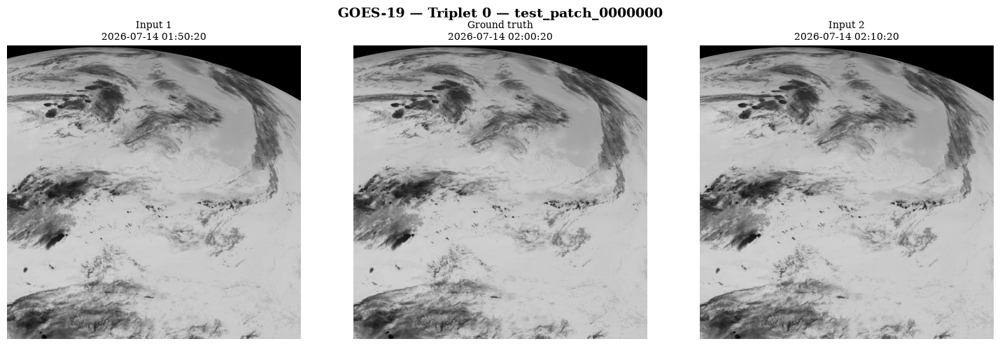

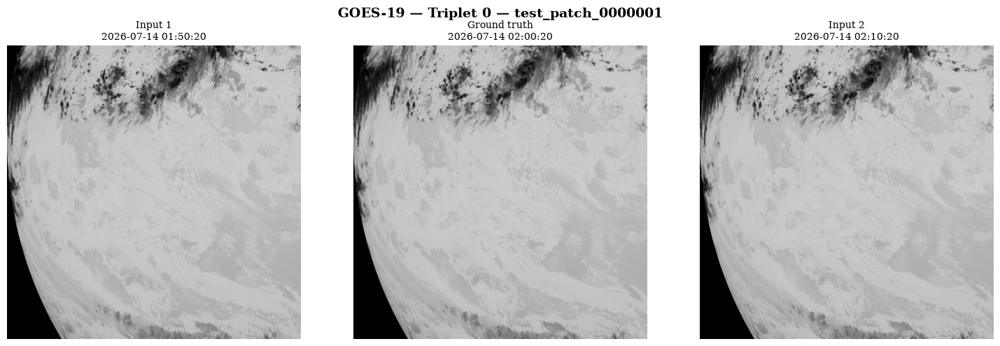

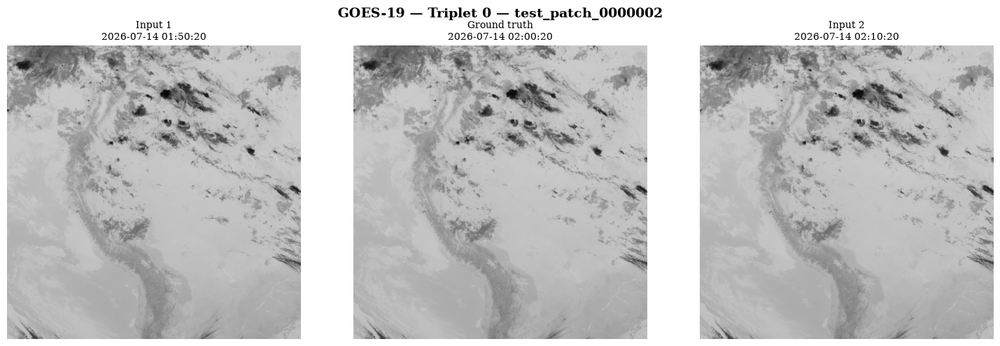

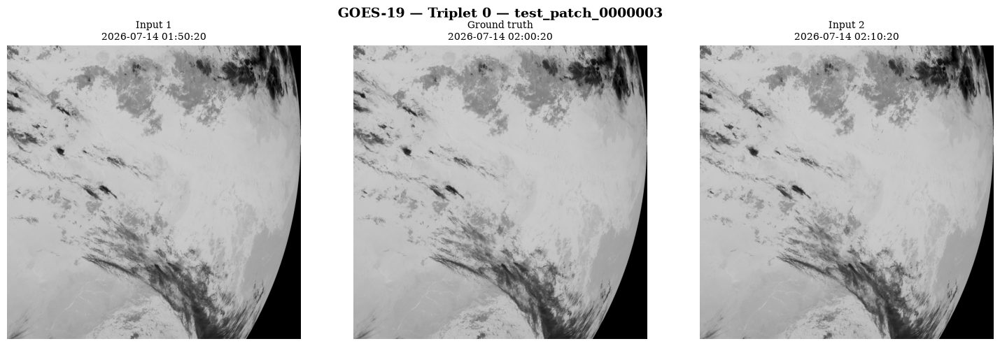

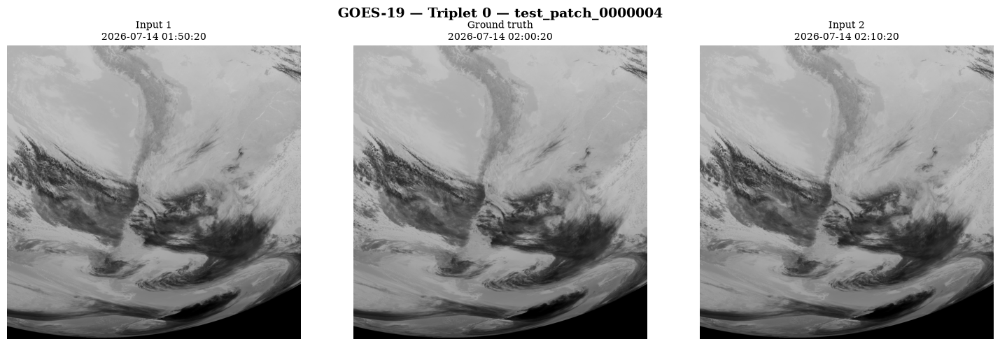

Selected-triplet patch images saved to: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_Patches


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

TRIPLET_CSV = (
    PROJECT_DIR / "Dataset" / "GOES_TestNEW" / "test_triplets.csv"
)
PATCH_CSV = (
    PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048" / "test_patches.csv"
)

OUTPUT_DIR = PROJECT_DIR / "results" / "One_Triplet_Patches"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the same index as the full-disk code.
TRIPLET_ROW_INDEX = 0

triplets = pd.read_csv(TRIPLET_CSV)
patches = pd.read_csv(PATCH_CSV)

triplet = triplets.iloc[TRIPLET_ROW_INDEX]

print("Selected triplet:")
print("Input 1:", triplet.get("time_0", "Unknown"))
print("Middle:", triplet.get("time_1", "Unknown"))
print("Input 2:", triplet.get("time_2", "Unknown"))

if "source_triplet_index" not in patches.columns:
    raise KeyError(
        "The patch CSV has no source_triplet_index column. "
        "Cannot reliably associate patches with this triplet."
    )

# Assumes source_triplet_index is the zero-based row index in triplets CSV.
selected_patches = patches[
    pd.to_numeric(patches["source_triplet_index"], errors="coerce")
    == TRIPLET_ROW_INDEX
].copy()

if selected_patches.empty:
    raise ValueError(
        f"No patches found for triplet row {TRIPLET_ROW_INDEX}. "
        "Check whether source_triplet_index uses a different ID convention."
    )

print(f"Number of patches for this triplet: {len(selected_patches)}")

def resolve_path(value):
    p = Path(str(value))
    return p if p.is_absolute() else PROJECT_DIR / p

def load_gray(path):
    path = resolve_path(path)

    if not path.exists():
        raise FileNotFoundError(path)

    if path.suffix.lower() == ".npy":
        arr = np.load(path)
    elif path.suffix.lower() == ".npz":
        z = np.load(path)
        arr = z[z.files[0]]
    else:
        arr = np.asarray(Image.open(path))

    arr = np.squeeze(arr).astype(np.float32)

    if arr.ndim != 2:
        raise ValueError(f"Expected grayscale patch, got {arr.shape}")

    if arr.max() > 1:
        arr /= 255.0

    return np.clip(arr, 0, 1)

for patch_num, (_, row) in enumerate(selected_patches.iterrows(), start=1):
    img0 = load_gray(row["img0_path"])
    gt = load_gray(row["gt_path"])
    img2 = load_gray(row["img2_path"])

    patch_id = str(row.get("patch_id", f"patch_{patch_num:03d}"))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(
        f"GOES-19 — Triplet {TRIPLET_ROW_INDEX} — {patch_id}",
        fontsize=14,
        fontweight="bold"
    )

    frames = [
        (img0, f"Input 1\n{triplet.get('time_0', 'Unknown')}"),
        (gt, f"Ground truth\n{triplet.get('time_1', 'Unknown')}"),
        (img2, f"Input 2\n{triplet.get('time_2', 'Unknown')}")
    ]

    for ax, (image, title) in zip(axes, frames):
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    fig.tight_layout()
    filename = f"triplet_{TRIPLET_ROW_INDEX:04d}_{patch_id}"
    fig.savefig(OUTPUT_DIR / f"{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Selected-triplet patch images saved to:", OUTPUT_DIR)

GOES-19 SUPER SLOMO PATCH EVALUATION
Device: cuda
GPU: NVIDIA H200 NVL
Patch CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset/GOES_TestPatches_2048/test_patches.csv
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/SuperSloMo_2048/epoch_100.pth
Output directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches

CSV columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
Total patch records: 1265

Triplet index 0: 5 patches selected.

Detected columns:
Input t0 : img0_path
GT t1    : gt_path
Input t2 : img2_path

SuperSloMo checkpoint loaded successfully.
Model class: SuperSloMo


Super SloMo patch prediction:   0%|          | 0/5 [00:00<?, ?it/s]

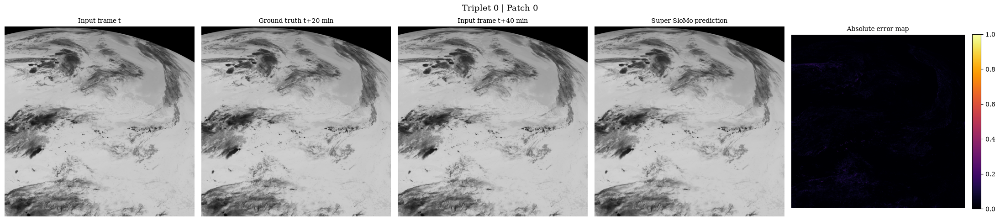


Patch 0 completed | MSE=0.000384 | MAE=0.009435 | PSNR=34.155 dB | time=0.22s


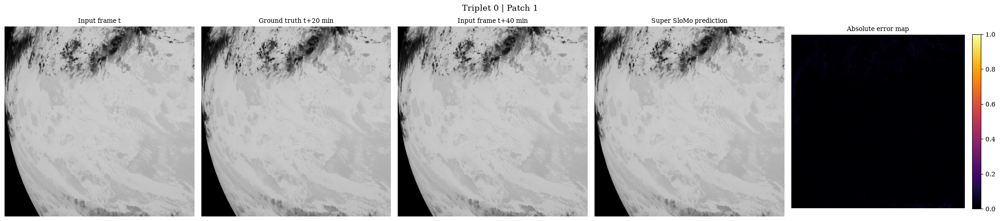


Patch 1 completed | MSE=0.000138 | MAE=0.005286 | PSNR=38.586 dB | time=0.19s


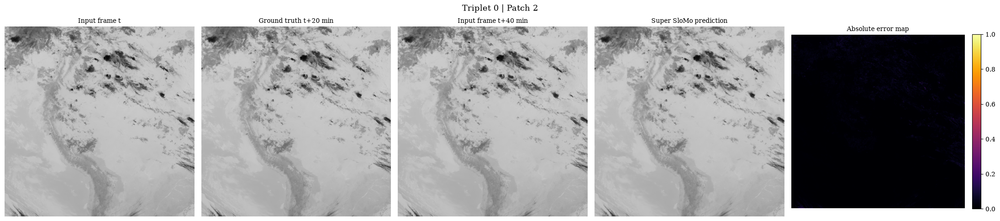


Patch 2 completed | MSE=0.000228 | MAE=0.006879 | PSNR=36.430 dB | time=0.20s


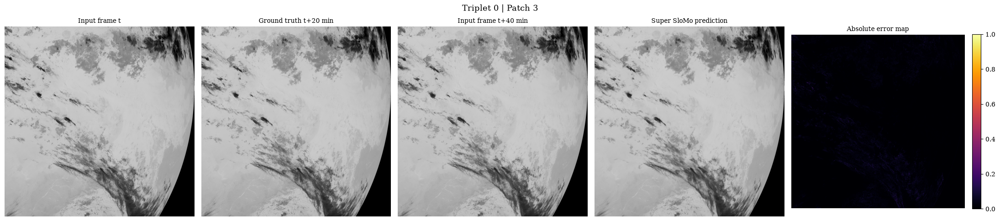


Patch 3 completed | MSE=0.000280 | MAE=0.008034 | PSNR=35.536 dB | time=0.22s


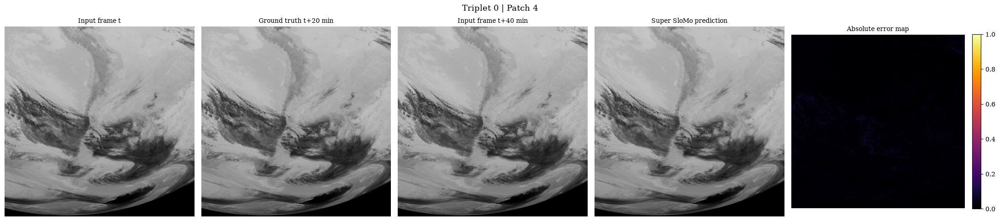


Patch 4 completed | MSE=0.000189 | MAE=0.006826 | PSNR=37.239 dB | time=0.23s

SUPER SLOMO EVALUATION COMPLETED
Triplet row index: 0
Patches evaluated: 5
Mean MSE  : 0.00024370
Mean MAE  : 0.00729205
Mean RMSE : 0.01538245
Mean PSNR : 36.3891 dB
Total runtime: 0.88 minutes

Metrics CSV:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches/triplet_0_patch_metrics.csv

Summary CSV:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches/triplet_0_summary.csv

Predictions:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches/predictions

Error maps:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches/error_maps

Plots:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Patches/plots

First rows of metrics:


,triplet_row_index,patch_number,input_t0_path,ground_truth_path,input_t2_path,prediction_path,error_map_path,plot_path,height,width,inference_seconds,MSE_normalized,MAE_normalized,RMSE_normalized,PSNR_dB,Bias_normalized
0,0,0,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2048,2048,0.221734,0.000384,0.009435,0.019599,34.155460,0.000383
1,0,1,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2048,2048,0.185939,0.000138,0.005286,0.011769,38.585558,0.000203
2,0,2,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2048,2048,0.204136,0.000228,0.006879,0.015083,36.430111,0.000364
3,0,3,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2048,2048,0.223760,0.000280,0.008034,0.016719,35.535622,0.000284
4,0,4,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,/home/kiruthigat.25mcse/Satellite_Frame_Interp...,2048,2048,0.227776,0.000189,0.006826,0.013742,37.238720,-0.000010


In [6]:

# ============================================================
# GOES-19 SUPER SLOMO — PATCH PREDICTION + ERROR MAP
#
# Model       : Trained Super SloMo
# Checkpoint  : epoch_100.pth
# Dataset     : GOES_TestPatches_2048
# Input       : Frame at t
# Ground truth: Frame at t + 20 minutes
# Input       : Frame at t + 40 minutes
# Prediction  : Intermediate frame at t + 20 minutes
#
# Output:
#   1. Input, ground truth, prediction and error-map plots
#   2. Predicted .npy files
#   3. Absolute-error .npy files
#   4. Per-patch MSE, MAE and PSNR CSV
#
# Super SloMo ONLY — no RIFE
# ============================================================

import os
import sys
import math
import time
import importlib.util
import inspect
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

PATCH_DIR = PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"
PATCH_CSV = PATCH_DIR / "test_patches.csv"

MODEL_FILE = PROJECT_DIR / "SuperSloMo" / "model.py"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "SuperSloMo_2048"
    / "epoch_100.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "One_Triplet_SuperSloMo_Patches"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"
ERROR_DIR = OUTPUT_DIR / "error_maps"
PLOT_DIR = OUTPUT_DIR / "plots"

for folder in [OUTPUT_DIR, PREDICTION_DIR, ERROR_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Set the row index of the original triplet you want to evaluate.
TRIPLET_ROW_INDEX = 0

# BT normalization used by the project: 200 K -> 0, 320 K -> 1.
BT_MIN = 200.0
BT_MAX = 320.0

PAD_MULTIPLE = 32
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 72)
print("GOES-19 SUPER SLOMO PATCH EVALUATION")
print("=" * 72)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Patch CSV:", PATCH_CSV)
print("Checkpoint:", CHECKPOINT_PATH)
print("Output directory:", OUTPUT_DIR)

# ============================================================
# 2. CHECK FILES
# ============================================================

if not PATCH_CSV.exists():
    raise FileNotFoundError(
        f"Patch CSV not found:\n{PATCH_CSV}\n"
        "Check the actual location of test_patches.csv."
    )

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"Super SloMo model file not found:\n{MODEL_FILE}"
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

# ============================================================
# 3. LOAD PATCH MANIFEST
# ============================================================

patches = pd.read_csv(PATCH_CSV)

print("\nCSV columns:", patches.columns.tolist())
print("Total patch records:", len(patches))

if "source_triplet_index" not in patches.columns:
    raise KeyError(
        "The patch CSV has no 'source_triplet_index' column. "
        f"Available columns: {patches.columns.tolist()}"
    )

patches["source_triplet_index"] = pd.to_numeric(
    patches["source_triplet_index"], errors="coerce"
)

selected_patches = patches[
    patches["source_triplet_index"] == TRIPLET_ROW_INDEX
].copy()

if selected_patches.empty:
    available = sorted(
        patches["source_triplet_index"].dropna().unique().tolist()
    )
    raise ValueError(
        f"No patches found for triplet index {TRIPLET_ROW_INDEX}.\n"
        f"Some available indices: {available[:30]}"
    )

print(
    f"\nTriplet index {TRIPLET_ROW_INDEX}: "
    f"{len(selected_patches)} patches selected."
)

# ============================================================
# 4. DETECT INPUT / TARGET / INPUT PATCH COLUMNS
# ============================================================

def find_column(columns, candidates, description):
    lower_map = {str(c).strip().lower(): c for c in columns}

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    for col in columns:
        low = str(col).strip().lower()
        if any(candidate.lower() in low for candidate in candidates):
            return col

    raise KeyError(
        f"Could not find the {description} column.\n"
        f"CSV columns: {list(columns)}\n"
        f"Candidates tried: {candidates}"
    )


COL_0 = find_column(
    patches.columns,
    [
        "img0_path", "input_0_path", "frame0_path",
        "img0", "input_0", "frame0", "t0_path", "path0"
    ],
    "first input frame"
)

COL_GT = find_column(
    patches.columns,
    [
        "gt_path", "target_path", "img1_path",
        "target", "ground_truth", "gt", "img1",
        "frame1", "t1_path", "path1"
    ],
    "ground-truth middle frame"
)

COL_2 = find_column(
    patches.columns,
    [
        "img2_path", "input_2_path", "frame2_path",
        "img2", "input_2", "frame2", "t2_path", "path2"
    ],
    "second input frame"
)

print("\nDetected columns:")
print("Input t0 :", COL_0)
print("GT t1    :", COL_GT)
print("Input t2 :", COL_2)

# ============================================================
# 5. RESOLVE PATCH PATHS
# ============================================================

def resolve_patch_path(value):
    if pd.isna(value):
        raise ValueError("Found an empty patch path in the CSV.")

    path = Path(str(value).strip())

    if path.is_absolute() and path.exists():
        return path

    candidates = [
        PROJECT_DIR / path,
        PATCH_DIR / path,
        PROJECT_DIR / "Dataset" / path,
    ]

    # If a path is stored relative to the patch dataset,
    # also try the basename in the usual frame folders.
    for candidate in candidates:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Could not resolve patch path: {value}\n"
        f"Tried:\n" + "\n".join(str(p) for p in candidates)
    )


# ============================================================
# 6. READ PATCHES
# ============================================================

def read_patch(path):
    path = resolve_patch_path(path)
    suffix = path.suffix.lower()

    if suffix == ".npy":
        image = np.load(path, allow_pickle=False)

    elif suffix == ".npz":
        data = np.load(path, allow_pickle=False)
        keys = list(data.keys())
        if not keys:
            raise ValueError(f"Empty NPZ file: {path}")
        image = data[keys[0]]

    else:
        image = np.asarray(Image.open(path))

    image = np.asarray(image, dtype=np.float32)
    image = np.squeeze(image)

    if image.ndim == 3:
        # Convert RGB-like patches to grayscale if necessary.
        if image.shape[-1] in (3, 4):
            image = image[..., :3].mean(axis=-1)
        elif image.shape[0] in (3, 4):
            image = image[:3].mean(axis=0)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got {image.shape}: {path}"
        )

    image = np.nan_to_num(
        image, nan=0.0, posinf=1.0, neginf=0.0
    )

    # These patch files are expected to be normalized to [0,1].
    # If stored as 8-bit images, convert to [0,1].
    if image.max() > 1.5 and image.min() >= 0 and image.max() <= 255:
        image = image / 255.0

    return np.clip(image, 0.0, 1.0).astype(np.float32)


# ============================================================
# 7. LOAD SUPERSLOMO MODEL
# ============================================================

spec = importlib.util.spec_from_file_location(
    "superslomo_model_module", str(MODEL_FILE)
)

if spec is None or spec.loader is None:
    raise ImportError(f"Cannot import model from {MODEL_FILE}")

superslomo_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = superslomo_module
spec.loader.exec_module(superslomo_module)

if not hasattr(superslomo_module, "SuperSloMo"):
    raise AttributeError(
        f"'SuperSloMo' class was not found in {MODEL_FILE}. "
        "Inspect model.py for the correct model class name."
    )

net = superslomo_module.SuperSloMo().to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Support common checkpoint dictionary formats.
if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model" in checkpoint and isinstance(checkpoint["model"], dict):
        state_dict = checkpoint["model"]
    elif "net" in checkpoint and isinstance(checkpoint["net"], dict):
        state_dict = checkpoint["net"]
    else:
        # Check whether this is already a state dictionary.
        state_dict = checkpoint
else:
    raise TypeError(
        f"Unsupported checkpoint type: {type(checkpoint)}"
    )

# Remove DataParallel prefix if present.
if state_dict and all(k.startswith("module.") for k in state_dict):
    state_dict = {
        k[len("module."):]: v for k, v in state_dict.items()
    }

try:
    net.load_state_dict(state_dict, strict=True)
except RuntimeError as exc:
    raise RuntimeError(
        "Checkpoint parameters do not match the SuperSloMo model "
        "defined in SuperSloMo/model.py. Make sure the model file and "
        "checkpoint are from the same training experiment.\n\n"
        f"Original error:\n{exc}"
    ) from exc

net.eval()

print("\nSuperSloMo checkpoint loaded successfully.")
print("Model class:", type(net).__name__)

# ============================================================
# 8. CONVERT PATCH TO SINGLE-CHANNEL TENSOR
# ============================================================

def to_tensor(image):
    """
    Convert [H,W] grayscale array to [1,1,H,W].
    The first convolution in the current flow-computation network
    expects concatenated single-channel images (2 input channels).
    """
    return torch.from_numpy(
        np.ascontiguousarray(image)
    ).float()[None, None].to(DEVICE)


# ============================================================
# 9. EXTRACT PREDICTION FROM MODEL OUTPUT
# ============================================================

def extract_prediction(output):
    if isinstance(output, dict):
        preferred_keys = [
            "frame", "prediction", "pred",
            "interpolated", "output"
        ]

        found = False
        for key in preferred_keys:
            if key in output and torch.is_tensor(output[key]):
                output = output[key]
                found = True
                break

        if not found:
            tensors = [
                value for value in output.values()
                if torch.is_tensor(value)
            ]
            if not tensors:
                raise TypeError(
                    "Model returned a dictionary without tensor outputs."
                )
            output = tensors[0]

    elif isinstance(output, (tuple, list)):
        if not output:
            raise TypeError("Model returned an empty tuple/list.")
        output = output[0]

    if not torch.is_tensor(output):
        raise TypeError(
            f"Unexpected model output type: {type(output)}"
        )

    if output.ndim == 3:
        output = output.unsqueeze(0)

    if output.ndim != 4:
        raise ValueError(
            f"Expected [B,C,H,W] model output; got {tuple(output.shape)}"
        )

    return output


# ============================================================
# 10. SUPERSLOMO MIDPOINT PREDICTION
# ============================================================

@torch.inference_mode()
def predict_superslomo(img0, img2):
    """
    Predict the midpoint between t0 and t2 using t=0.5.
    Input arrays must be grayscale and normalized to [0,1].
    """
    height, width = img0.shape

    a = to_tensor(img0)
    b = to_tensor(img2)

    pad_h = (PAD_MULTIPLE - height % PAD_MULTIPLE) % PAD_MULTIPLE
    pad_w = (PAD_MULTIPLE - width % PAD_MULTIPLE) % PAD_MULTIPLE

    if pad_h or pad_w:
        a = F.pad(
            a, (0, pad_w, 0, pad_h), mode="replicate"
        )
        b = F.pad(
            b, (0, pad_w, 0, pad_h), mode="replicate"
        )

    # Try the keyword form first, then positional t=0.5.
    try:
        output = net(a, b, t=0.5)
    except TypeError:
        output = net(a, b, 0.5)

    output = extract_prediction(output)

    # Crop off padding.
    output = output[0, :, :height, :width]

    # Collapse channels if model returns multiple channels.
    if output.shape[0] == 1:
        prediction = output[0]
    else:
        prediction = output.mean(dim=0)

    prediction = prediction.float().cpu().numpy()
    prediction = np.nan_to_num(
        prediction, nan=0.0, posinf=1.0, neginf=0.0
    )
    prediction = np.clip(prediction, 0.0, 1.0).astype(np.float32)

    del a, b, output
    return prediction


# ============================================================
# 11. METRIC HELPERS
# ============================================================

def calculate_metrics(prediction, target):
    """
    Metrics calculated on normalized [0,1] patches.
    PSNR is reported in dB.
    """
    error = prediction - target
    abs_error = np.abs(error)

    mse = float(np.mean(error ** 2))
    mae = float(np.mean(abs_error))
    rmse = float(np.sqrt(mse))

    if mse == 0:
        psnr = float("inf")
    else:
        psnr = float(10.0 * np.log10(1.0 / mse))

    bias = float(np.mean(error))

    return {
        "MSE_normalized": mse,
        "MAE_normalized": mae,
        "RMSE_normalized": rmse,
        "PSNR_dB": psnr,
        "Bias_normalized": bias,
    }


# ============================================================
# 12. PLOT PATCHES AND ERROR MAP
# ============================================================

def save_plot(img0, gt, img2, prediction, error_map,
              patch_number, metrics, paths):
    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    panels = [
        (img0, "Input frame t"),
        (gt, "Ground truth t+20 min"),
        (img2, "Input frame t+40 min"),
        (prediction, "Super SloMo prediction"),
        (error_map, "Absolute error map"),
    ]

    for ax, (image, title) in zip(axes, panels):
        if title == "Absolute error map":
            im = ax.imshow(image, cmap="inferno", vmin=0.0, vmax=1.0)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        else:
            ax.imshow(image, cmap="gray", vmin=0.0, vmax=1.0)

        ax.set_title(title, fontsize=10)
        ax.axis("off")

    fig.suptitle(
        f"Triplet {TRIPLET_ROW_INDEX} | Patch {patch_number}",
        fontsize=13
    )
    fig.tight_layout()

    plot_path = PLOT_DIR / f"triplet_{TRIPLET_ROW_INDEX}_patch_{patch_number:05d}.png"
    fig.savefig(plot_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return plot_path


# ============================================================
# 13. PROCESS ALL PATCHES FOR SELECTED TRIPLET
# ============================================================

records = []
total_start = time.time()

for local_index, (_, row) in enumerate(
    tqdm(selected_patches.iterrows(), total=len(selected_patches),
         desc="Super SloMo patch prediction")
):
    try:
        path0 = resolve_patch_path(row[COL_0])
        path_gt = resolve_patch_path(row[COL_GT])
        path2 = resolve_patch_path(row[COL_2])

        img0 = read_patch(path0)
        gt = read_patch(path_gt)
        img2 = read_patch(path2)

        if img0.shape != gt.shape or img0.shape != img2.shape:
            raise ValueError(
                "Patch dimensions do not match: "
                f"t0={img0.shape}, GT={gt.shape}, t2={img2.shape}"
            )

        start = time.time()
        prediction = predict_superslomo(img0, img2)
        inference_seconds = time.time() - start

        if prediction.shape != gt.shape:
            raise ValueError(
                f"Prediction shape {prediction.shape} "
                f"does not match GT shape {gt.shape}"
            )

        error_map = np.abs(prediction - gt)
        metrics = calculate_metrics(prediction, gt)

        patch_number = local_index

        pred_path = (
            PREDICTION_DIR
            / f"triplet_{TRIPLET_ROW_INDEX}_patch_{patch_number:05d}.npy"
        )
        error_path = (
            ERROR_DIR
            / f"triplet_{TRIPLET_ROW_INDEX}_patch_{patch_number:05d}.npy"
        )

        np.save(pred_path, prediction)
        np.save(error_path, error_map)

        plot_path = save_plot(
            img0, gt, img2, prediction, error_map,
            patch_number, metrics,
            (path0, path_gt, path2)
        )

        record = {
            "triplet_row_index": TRIPLET_ROW_INDEX,
            "patch_number": patch_number,
            "input_t0_path": str(path0),
            "ground_truth_path": str(path_gt),
            "input_t2_path": str(path2),
            "prediction_path": str(pred_path),
            "error_map_path": str(error_path),
            "plot_path": str(plot_path),
            "height": int(gt.shape[0]),
            "width": int(gt.shape[1]),
            "inference_seconds": float(inference_seconds),
            **metrics,
        }

        records.append(record)

        print(
            f"\nPatch {patch_number} completed | "
            f"MSE={metrics['MSE_normalized']:.6f} | "
            f"MAE={metrics['MAE_normalized']:.6f} | "
            f"PSNR={metrics['PSNR_dB']:.3f} dB | "
            f"time={inference_seconds:.2f}s"
        )

    except Exception as exc:
        print(
            f"\nERROR processing patch {local_index}: "
            f"{type(exc).__name__}: {exc}"
        )
        raise

# ============================================================
# 14. SAVE METRICS AND SUMMARY
# ============================================================

if not records:
    raise RuntimeError("No patches were successfully evaluated.")

metrics_df = pd.DataFrame(records)

metrics_csv = OUTPUT_DIR / (
    f"triplet_{TRIPLET_ROW_INDEX}_patch_metrics.csv"
)
metrics_df.to_csv(metrics_csv, index=False)

numeric_cols = [
    "MSE_normalized",
    "MAE_normalized",
    "RMSE_normalized",
    "PSNR_dB",
    "Bias_normalized",
    "inference_seconds",
]

summary = {
    "triplet_row_index": TRIPLET_ROW_INDEX,
    "number_of_patches": len(metrics_df),
}

for col in numeric_cols:
    summary[f"mean_{col}"] = float(metrics_df[col].mean())

summary_csv = OUTPUT_DIR / (
    f"triplet_{TRIPLET_ROW_INDEX}_summary.csv"
)
pd.DataFrame([summary]).to_csv(summary_csv, index=False)

# ============================================================
# 15. FINAL REPORT
# ============================================================

print("\n" + "=" * 72)
print("SUPER SLOMO EVALUATION COMPLETED")
print("=" * 72)

print("Triplet row index:", TRIPLET_ROW_INDEX)
print("Patches evaluated:", len(metrics_df))
print(f"Mean MSE  : {metrics_df['MSE_normalized'].mean():.8f}")
print(f"Mean MAE  : {metrics_df['MAE_normalized'].mean():.8f}")
print(f"Mean RMSE : {metrics_df['RMSE_normalized'].mean():.8f}")
print(f"Mean PSNR : {metrics_df['PSNR_dB'].mean():.4f} dB")
print(
    f"Total runtime: {(time.time() - total_start) / 60:.2f} minutes"
)

print("\nMetrics CSV:")
print(metrics_csv)

print("\nSummary CSV:")
print(summary_csv)

print("\nPredictions:")
print(PREDICTION_DIR)

print("\nError maps:")
print(ERROR_DIR)

print("\nPlots:")
print(PLOT_DIR)

print("\nFirst rows of metrics:")
display(metrics_df.head())


GOES-19 SUPER SLOMO — PATCH PREDICTION
Device: cuda
GPU: NVIDIA H200 NVL
Triplet index: 0
Number of patches: 5
CSV columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
Input t0 column: img0_path
Ground-truth column: gt_path
Input t2 column: img2_path

Super SloMo checkpoint loaded successfully.


Predicting intermediate frames:   0%|          | 0/5 [00:00<?, ?it/s]

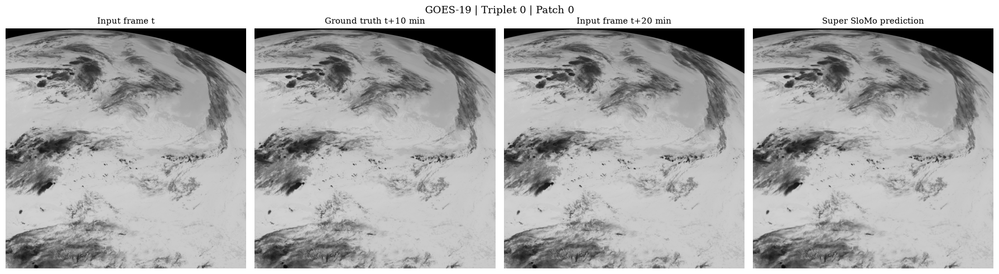

Patch 0 prediction saved.


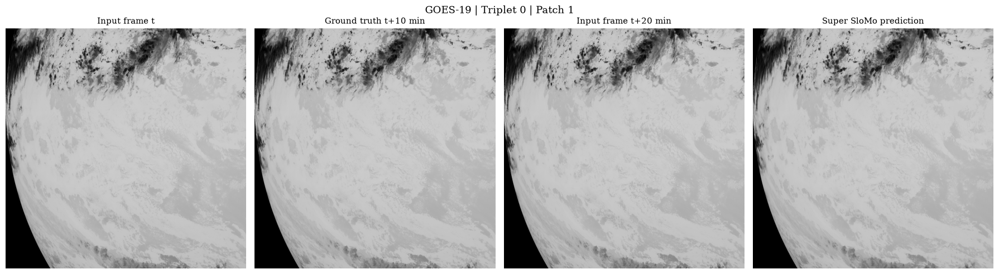

Patch 1 prediction saved.


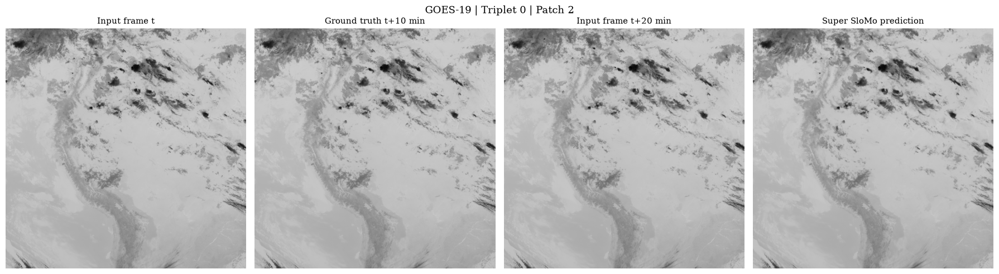

Patch 2 prediction saved.


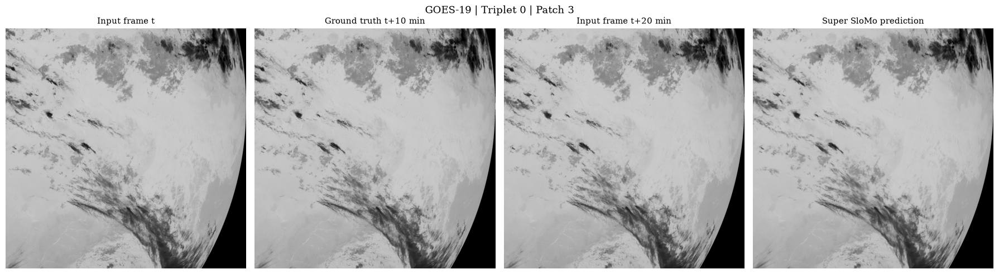

Patch 3 prediction saved.


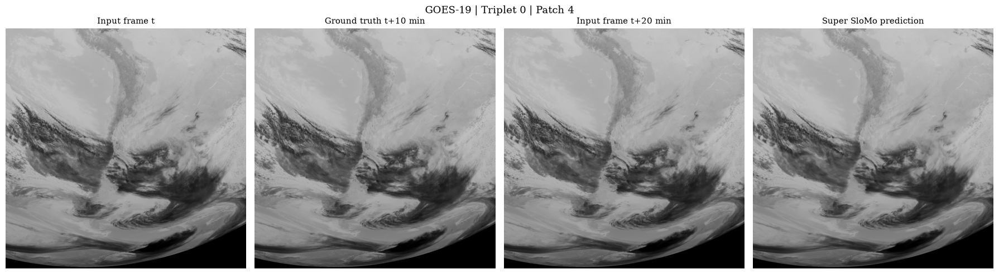

Patch 4 prediction saved.

PREDICTION COMPLETED
Triplet index: 0
Patches predicted: 5
Prediction folder: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Predictions/predictions
Plot folder: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Predictions/plots
Prediction file list: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/One_Triplet_SuperSloMo_Predictions/triplet_0_prediction_files.csv
Total time: 0.71 minutes


In [6]:

# ============================================================
# GOES-19 SUPER SLOMO — PATCH PREDICTION ONLY
#
# Input  : Frame t
# Target : Ground-truth frame at t + 20 minutes
# Input  : Frame t + 40 minutes
# Output : Predicted intermediate frame at t + 20 minutes
#
# No error map
# No metric calculations or metric values
# No training
# ============================================================

import sys
import time
import importlib.util
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

PATCH_DIR = PROJECT_DIR / "Dataset" / "GOES_TestPatches_2048"
PATCH_CSV = PATCH_DIR / "test_patches.csv"

MODEL_FILE = PROJECT_DIR / "SuperSloMo" / "model.py"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "SuperSloMo_2048"
    / "epoch_100.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "One_Triplet_SuperSloMo_Predictions"
)

PREDICTION_DIR = OUTPUT_DIR / "predictions"
PLOT_DIR = OUTPUT_DIR / "plots"

PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TRIPLET_ROW_INDEX = 0
PAD_MULTIPLE = 32

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("GOES-19 SUPER SLOMO — PATCH PREDICTION")
print("=" * 65)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 2. CHECK FILES
# ============================================================

for path in [PATCH_CSV, MODEL_FILE, CHECKPOINT_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# ============================================================
# 3. LOAD PATCH CSV AND SELECT ONE TRIPLET
# ============================================================

patches = pd.read_csv(PATCH_CSV)

if "source_triplet_index" not in patches.columns:
    raise KeyError(
        "Missing source_triplet_index column. "
        f"Available columns: {patches.columns.tolist()}"
    )

patches["source_triplet_index"] = pd.to_numeric(
    patches["source_triplet_index"],
    errors="coerce"
)

selected_patches = patches[
    patches["source_triplet_index"] == TRIPLET_ROW_INDEX
].copy()

if selected_patches.empty:
    raise ValueError(
        f"No patches found for triplet index {TRIPLET_ROW_INDEX}."
    )

print("Triplet index:", TRIPLET_ROW_INDEX)
print("Number of patches:", len(selected_patches))
print("CSV columns:", patches.columns.tolist())

# ============================================================
# 4. DETECT PATH COLUMNS
# ============================================================

def find_column(columns, candidates, description):
    lower_map = {
        str(c).strip().lower(): c
        for c in columns
    }

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    for col in columns:
        low = str(col).strip().lower()
        if any(candidate.lower() in low for candidate in candidates):
            return col

    raise KeyError(
        f"Cannot identify {description} column.\n"
        f"Available columns: {list(columns)}"
    )


COL_0 = find_column(
    patches.columns,
    [
        "img0_path", "input_0_path", "frame0_path",
        "img0", "input_0", "frame0", "t0_path", "path0"
    ],
    "first input frame"
)

COL_GT = find_column(
    patches.columns,
    [
        "gt_path", "target_path", "img1_path",
        "target", "ground_truth", "gt", "img1",
        "frame1", "t1_path", "path1"
    ],
    "ground-truth frame"
)

COL_2 = find_column(
    patches.columns,
    [
        "img2_path", "input_2_path", "frame2_path",
        "img2", "input_2", "frame2", "t2_path", "path2"
    ],
    "second input frame"
)

print("Input t0 column:", COL_0)
print("Ground-truth column:", COL_GT)
print("Input t2 column:", COL_2)

# ============================================================
# 5. RESOLVE PATCH PATHS
# ============================================================

def resolve_patch_path(value):
    if pd.isna(value):
        raise ValueError("Empty patch path in CSV.")

    path = Path(str(value).strip())

    candidates = [
        path,
        PROJECT_DIR / path,
        PATCH_DIR / path,
        PROJECT_DIR / "Dataset" / path,
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    raise FileNotFoundError(
        f"Cannot find patch: {value}\n"
        f"Tried: {[str(p) for p in candidates]}"
    )

# ============================================================
# 6. READ GRAYSCALE PATCH
# ============================================================

def read_patch(value):
    path = resolve_patch_path(value)
    suffix = path.suffix.lower()

    if suffix == ".npy":
        image = np.load(path, allow_pickle=False)

    elif suffix == ".npz":
        archive = np.load(path, allow_pickle=False)
        if not archive.files:
            raise ValueError(f"Empty NPZ file: {path}")
        image = archive[archive.files[0]]

    else:
        image = np.asarray(Image.open(path))

    image = np.asarray(image, dtype=np.float32)
    image = np.squeeze(image)

    if image.ndim == 3:
        if image.shape[-1] in (3, 4):
            image = image[..., :3].mean(axis=-1)
        elif image.shape[0] in (3, 4):
            image = image[:3].mean(axis=0)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale patch, got {image.shape}: {path}"
        )

    image = np.nan_to_num(
        image, nan=0.0, posinf=1.0, neginf=0.0
    )

    if image.max() > 1.5 and image.min() >= 0 and image.max() <= 255:
        image = image / 255.0

    return np.clip(image, 0.0, 1.0).astype(np.float32)

# ============================================================
# 7. LOAD SUPERSLOMO MODEL AND CHECKPOINT
# ============================================================

spec = importlib.util.spec_from_file_location(
    "superslomo_model_module",
    str(MODEL_FILE)
)

if spec is None or spec.loader is None:
    raise ImportError(f"Cannot import model: {MODEL_FILE}")

superslomo_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = superslomo_module
spec.loader.exec_module(superslomo_module)

if not hasattr(superslomo_module, "SuperSloMo"):
    raise AttributeError(
        "SuperSloMo class not found in SuperSloMo/model.py"
    )

net = superslomo_module.SuperSloMo().to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif "model" in checkpoint and isinstance(checkpoint["model"], dict):
    state_dict = checkpoint["model"]
elif "net" in checkpoint and isinstance(checkpoint["net"], dict):
    state_dict = checkpoint["net"]
else:
    state_dict = checkpoint

if state_dict and all(k.startswith("module.") for k in state_dict):
    state_dict = {
        k[len("module."):]: v
        for k, v in state_dict.items()
    }

net.load_state_dict(state_dict, strict=True)
net.eval()

print("\nSuper SloMo checkpoint loaded successfully.")

# ============================================================
# 8. CONVERT IMAGE TO TENSOR
# ============================================================

def to_tensor(image):
    return torch.from_numpy(
        np.ascontiguousarray(image)
    ).float()[None, None].to(DEVICE)

# ============================================================
# 9. EXTRACT PREDICTED FRAME
# ============================================================

def extract_prediction(output):
    if isinstance(output, dict):
        for key in [
            "frame", "prediction", "pred",
            "interpolated", "output"
        ]:
            if key in output and torch.is_tensor(output[key]):
                output = output[key]
                break
        else:
            tensor_values = [
                value for value in output.values()
                if torch.is_tensor(value)
            ]
            if not tensor_values:
                raise TypeError(
                    "Model output dictionary contains no tensors."
                )
            output = tensor_values[0]

    elif isinstance(output, (tuple, list)):
        if not output:
            raise TypeError("Model returned an empty tuple/list.")
        output = output[0]

    if not torch.is_tensor(output):
        raise TypeError(
            f"Unexpected model output type: {type(output)}"
        )

    if output.ndim == 3:
        output = output.unsqueeze(0)

    if output.ndim != 4:
        raise ValueError(
            f"Unexpected output shape: {tuple(output.shape)}"
        )

    return output

# ============================================================
# 10. PREDICT INTERMEDIATE FRAME
# ============================================================

@torch.inference_mode()
def predict_superslomo(img0, img2):
    height, width = img0.shape

    tensor0 = to_tensor(img0)
    tensor2 = to_tensor(img2)

    pad_h = (PAD_MULTIPLE - height % PAD_MULTIPLE) % PAD_MULTIPLE
    pad_w = (PAD_MULTIPLE - width % PAD_MULTIPLE) % PAD_MULTIPLE

    if pad_h or pad_w:
        tensor0 = F.pad(
            tensor0, (0, pad_w, 0, pad_h), mode="replicate"
        )
        tensor2 = F.pad(
            tensor2, (0, pad_w, 0, pad_h), mode="replicate"
        )

    try:
        output = net(tensor0, tensor2, t=0.5)
    except TypeError:
        output = net(tensor0, tensor2, 0.5)

    output = extract_prediction(output)
    output = output[0, :, :height, :width]

    if output.shape[0] == 1:
        prediction = output[0]
    else:
        prediction = output.mean(dim=0)

    prediction = prediction.float().cpu().numpy()
    prediction = np.nan_to_num(
        prediction, nan=0.0, posinf=1.0, neginf=0.0
    )
    prediction = np.clip(prediction, 0.0, 1.0).astype(np.float32)

    del tensor0, tensor2, output

    return prediction

# ============================================================
# 11. PREDICT AND DISPLAY ALL SELECTED PATCHES
# ============================================================

records = []
start_time = time.time()

for patch_number, (_, row) in enumerate(
    tqdm(
        selected_patches.iterrows(),
        total=len(selected_patches),
        desc="Predicting intermediate frames"
    )
):
    path0 = resolve_patch_path(row[COL_0])
    path_gt = resolve_patch_path(row[COL_GT])
    path2 = resolve_patch_path(row[COL_2])

    img0 = read_patch(path0)
    ground_truth = read_patch(path_gt)
    img2 = read_patch(path2)

    if img0.shape != ground_truth.shape or img0.shape != img2.shape:
        raise ValueError(
            f"Patch shapes differ: {img0.shape}, "
            f"{ground_truth.shape}, {img2.shape}"
        )

    prediction = predict_superslomo(img0, img2)

    if prediction.shape != ground_truth.shape:
        raise ValueError(
            f"Prediction shape {prediction.shape} differs from "
            f"ground truth {ground_truth.shape}"
        )

    # Save predicted frame only.
    prediction_path = (
        PREDICTION_DIR
        / f"triplet_{TRIPLET_ROW_INDEX}_patch_{patch_number:05d}.npy"
    )
    np.save(prediction_path, prediction)

    # Plot four images only; no error map and no metric values.
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    images = [
        (img0, "Input frame t"),
        (ground_truth, "Ground truth t+10 min"),
        (img2, "Input frame t+20 min"),
        (prediction, "Super SloMo prediction"),
    ]

    for ax, (image, title) in zip(axes, images):
        ax.imshow(image, cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_title(title, fontsize=11)
        ax.axis("off")

    fig.suptitle(
        f"GOES-19 | Triplet {TRIPLET_ROW_INDEX} | Patch {patch_number}",
        fontsize=13
    )
    fig.tight_layout()

    plot_path = (
        PLOT_DIR
        / f"triplet_{TRIPLET_ROW_INDEX}_patch_{patch_number:05d}.png"
    )
    fig.savefig(plot_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    records.append({
        "triplet_row_index": TRIPLET_ROW_INDEX,
        "patch_number": patch_number,
        "prediction_path": str(prediction_path),
        "plot_path": str(plot_path),
    })

    print(f"Patch {patch_number} prediction saved.")

# ============================================================
# 12. SAVE PREDICTION FILE LIST
# ============================================================

output_csv = OUTPUT_DIR / (
    f"triplet_{TRIPLET_ROW_INDEX}_prediction_files.csv"
)

pd.DataFrame(records).to_csv(output_csv, index=False)

print("\n" + "=" * 65)
print("PREDICTION COMPLETED")
print("=" * 65)
print("Triplet index:", TRIPLET_ROW_INDEX)
print("Patches predicted:", len(records))
print("Prediction folder:", PREDICTION_DIR)
print("Plot folder:", PLOT_DIR)
print("Prediction file list:", output_csv)
print(f"Total time: {(time.time() - start_time) / 60:.2f} minutes")
